# **Diplomatura en Ciencia de Datos, Aprendizaje Automático y sus Aplicaciones**

### **Edición 2025**

---

## Trabajo práctico entregable - Aprendizaje No Supervisado

## Grupo 34 :

  * Ana Luz Alabi Nassr
  * Felipe Ávila
  * Grisel Britos
  * Sofía Perón Santana
  * Paula Nieto

In [139]:
# Instalación de librerías necesarias
!pip install dash jupyter-dash yellowbrick

import numpy as np
import pandas as pd
import warnings

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 1000)
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objs as go
from plotly.offline import init_notebook_mode
from yellowbrick.cluster import KElbowVisualizer

init_notebook_mode(connected=True)

import dash
from dash import dcc, html
from jupyter_dash import JupyterDash

from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

from sklearn.cluster import KMeans, DBSCAN, MeanShift, estimate_bandwidth
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    calinski_harabasz_score,
    davies_bouldin_score
)

from matplotlib.lines import Line2D


## 1. Análisis exploratorio de la base de datos

Consignas que se responden en esta sección:
1. Análisis exploratorio inicial de la base.
2. Evaluación visual e intuitiva de a dos variables numéricas por vez.

### 1.1. Carga de la base de datos

In [2]:
# cargamos la url de la nueva base de datos
url = "https://raw.githubusercontent.com/DiploDatos/AprendizajeNOSupervisado/master/2024/2025/male_players.csv"
df = pd.read_csv(url)
df.head()

,Unnamed: 0.1,Unnamed: 0,Rank,Name,OVR,PAC,SHO,PAS,DRI,DEF,PHY,Acceleration,Sprint Speed,Positioning,Finishing,Shot Power,Long Shots,Volleys,Penalties,Vision,Crossing,Free Kick Accuracy,Short Passing,Long Passing,Curve,Dribbling,Agility,Balance,Reactions,Ball Control,Composure,Interceptions,Heading Accuracy,Def Awareness,Standing Tackle,Sliding Tackle,Jumping,Stamina,Strength,Aggression,Position,Weak foot,Skill moves,Preferred foot,Height,Weight,Alternative positions,Age,Nation,League,Team,play style,url,GK Diving,GK Handling,GK Kicking,GK Positioning,GK Reflexes
0,0,0,1,Kylian Mbappé,91,97,90,80,92,36,78,97,97,93,94,90,83,84,84,83,78,69,86,71,80,93,93,82,93,92,88,38,73,26,34,32,88,88,77,64,ST,4,5,Right,"182cm / 6'0""",75kg / 165lb,LW,25,France,LALIGA EA SPORTS,Real Madrid,"Quick Step+, Acrobatic, Finesse Shot, Flair, R...",https://www.ea.com/games/ea-sports-fc/ratings/...,NaN,NaN,NaN,NaN,NaN
1,1,1,2,Rodri,91,66,80,86,84,87,85,65,66,76,74,92,89,71,62,84,76,64,93,91,86,84,66,67,93,90,94,84,81,92,87,82,83,91,83,85,CDM,4,3,Right,"191cm / 6'3""",82kg / 181lb,CM,28,Spain,Premier League,Manchester City,"Tiki Taka+, Aerial, Bruiser, Long Ball Pass, P...",https://www.ea.com/games/ea-sports-fc/ratings/...,NaN,NaN,NaN,NaN,NaN
2,2,2,4,Erling Haaland,91,88,92,70,81,45,88,80,94,96,96,94,83,90,90,74,58,62,77,66,77,79,77,69,94,83,87,43,83,38,47,29,92,76,93,88,ST,3,3,Left,"195cm / 6'5""",94kg / 207lb,NaN,24,Norway,Premier League,Manchester City,"Acrobatic+, Bruiser, Power Header, Power Shot,...",https://www.ea.com/games/ea-sports-fc/ratings/...,NaN,NaN,NaN,NaN,NaN
3,3,3,5,Jude Bellingham,90,80,87,83,88,78,83,81,80,91,90,85,86,77,74,90,66,68,89,89,73,89,82,79,91,89,87,82,75,77,79,77,84,93,77,85,CAM,4,4,Right,"186cm / 6'1""",75kg / 165lb,CM,21,England,LALIGA EA SPORTS,Real Madrid,"Relentless+, Flair, Intercept, Slide Tackle, T...",https://www.ea.com/games/ea-sports-fc/ratings/...,NaN,NaN,NaN,NaN,NaN
4,4,4,7,Vini Jr.,90,95,84,81,91,29,69,95,95,87,89,81,83,73,71,85,81,62,83,77,79,93,94,84,86,90,83,26,50,32,25,18,74,84,65,58,LW,4,5,Right,"176cm / 5'9""",73kg / 161lb,"ST, LM",24,Brazil,LALIGA EA SPORTS,Real Madrid,"Quick Step+, Chip Shot, Finesse Shot, First To...",https://www.ea.com/games/ea-sports-fc/ratings/...,NaN,NaN,NaN,NaN,NaN


Observamos las columnas presentes, en nuestra base de datos.

In [3]:
df.columns 

Index(['Unnamed: 0.1', 'Unnamed: 0', 'Rank', 'Name', 'OVR', 'PAC', 'SHO',
       'PAS', 'DRI', 'DEF', 'PHY', 'Acceleration', 'Sprint Speed',
       'Positioning', 'Finishing', 'Shot Power', 'Long Shots', 'Volleys',
       'Penalties', 'Vision', 'Crossing', 'Free Kick Accuracy',
       'Short Passing', 'Long Passing', 'Curve', 'Dribbling', 'Agility',
       'Balance', 'Reactions', 'Ball Control', 'Composure', 'Interceptions',
       'Heading Accuracy', 'Def Awareness', 'Standing Tackle',
       'Sliding Tackle', 'Jumping', 'Stamina', 'Strength', 'Aggression',
       'Position', 'Weak foot', 'Skill moves', 'Preferred foot', 'Height',
       'Weight', 'Alternative positions', 'Age', 'Nation', 'League', 'Team',
       'play style', 'url', 'GK Diving', 'GK Handling', 'GK Kicking',
       'GK Positioning', 'GK Reflexes'],
      dtype='object')

### 1.2.Variables presentes en la base de datos

A continuación presentamos las distintas variables y su significado

---


####  Información Personal

| **Variable**             | **Significado**                                | **Variable**            | **Significado**                                | **Variable**            | **Significado**                                |
|--------------------------|------------------------------------------------|-------------------------|------------------------------------------------|-------------------------|------------------------------------------------|
| **Name**                 | Nombre del jugador.                            | **url**                 | Enlace a la página oficial.                    | **Position**            | Posición principal (ST, CAM, CB…).             |
| **Alternativepositions** | Posiciones alternativas.                       | **Weakfoot**            | Pierna débil (1 a 5).                          | **Skillmoves**          | Estrellas de skill moves (1 a 5).              |
| **Preferredfoot**        | Pie preferido (izq. / der.).                   | **Height**              | Altura.                                        | **Weight**              | Peso.                                          |
| **Age**                  | Edad.                                          | **Nation**              | Nacionalidad.                                  | **League**              | Liga.                                          |
| **Team**                 | Club actual.                                   | **playstyle**           | Estilo de juego (EA FC 24).                    |                         |                                                |

---


####  Atributos de Jugador

| **Variable**             | **Significado**                                | **Variable**            | **Significado**                                | **Variable**            | **Significado**                                |
|--------------------------|------------------------------------------------|-------------------------|------------------------------------------------|-------------------------|------------------------------------------------|
| **OVR**                  | Valoración general (Overall).                  | **PAC**                 | Ritmo / velocidad.                             | **SHO**                 | Disparo.                                       |
| **PAS**                  | Pases.                                         | **DRI**                 | Regate.                                        | **DEF**                 | Defensa.                                       |
| **PHY**                  | Físico.                                        | **Acceleration**        | Aceleración.                                   | **SprintSpeed**         | Velocidad máxima.                              |
| **Positioning**          | Colocación ofensiva.                           | **Finishing**           | Definición.                                    | **ShotPower**           | Potencia de tiro.                              |
| **LongShots**            | Tiros lejanos.                                 | **Volleys**             | Volea.                                         | **Penalties**           | Penales.                                       |
| **Vision**               | Visión de juego.                               | **Crossing**            | Centros.                                       | **FreeKickAccuracy**    | Precisión en tiros libres.                     |
| **ShortPassing**         | Pase corto.                                    | **LongPassing**         | Pase largo.                                    | **Curve**               | Efecto / curva del balón.                      |
| **Dribbling**            | Regate.                                        | **Agility**             | Agilidad.                                      | **Balance**             | Equilibrio.                                    |
| **Reactions**            | Reacciones.                                    | **BallControl**         | Control de balón.                              | **Composure**           | Compostura (calma bajo presión).               |
| **Interceptions**        | Intercepciones.                                | **HeadingAccuracy**     | Precisión de cabeza.                           | **DefAwareness**        | Conciencia defensiva.                          |
| **StandingTackle**       | Entrada normal.                                | **SlidingTackle**       | Entrada al ras.                                | **Jumping**             | Salto.                                         |
| **Stamina**              | Resistencia.                                   | **Strength**            | Fuerza.                                        | **Aggression**          | Agresividad.                                   |

---

####  Atributos de Portero

| **Variable**             | **Significado**                                | **Variable**            | **Significado**                                | **Variable**            | **Significado**                                |
|--------------------------|------------------------------------------------|-------------------------|------------------------------------------------|-------------------------|------------------------------------------------|
| **GKDiving**             | Estirada.                                      | **GKHandling**          | Manejo de balón.                               | **GKKicking**           | Saque / patada.                               |
| **GKPositioning**        | Colocación.                                    | **GKReflexes**          | Reflejos.                                      |                         |                                                |

Podemos diferenciar 47 columnas numéricas y 11 columnas categóricas.

In [4]:
columnas_numericas = df.select_dtypes(include=['number']).columns  # seleccionamos columnas numericas
columnas_categoricas = df.select_dtypes(include=['object']).columns # seleccionamos columnas categoricas

print("Columnas numéricas:",len(columnas_numericas),"\n",columnas_numericas)
print("Columnas categóricas:",len(columnas_categoricas),"\n",columnas_categoricas)

Columnas numéricas: 47 
 Index(['Unnamed: 0.1', 'Unnamed: 0', 'Rank', 'OVR', 'PAC', 'SHO', 'PAS', 'DRI',
       'DEF', 'PHY', 'Acceleration', 'Sprint Speed', 'Positioning',
       'Finishing', 'Shot Power', 'Long Shots', 'Volleys', 'Penalties',
       'Vision', 'Crossing', 'Free Kick Accuracy', 'Short Passing',
       'Long Passing', 'Curve', 'Dribbling', 'Agility', 'Balance', 'Reactions',
       'Ball Control', 'Composure', 'Interceptions', 'Heading Accuracy',
       'Def Awareness', 'Standing Tackle', 'Sliding Tackle', 'Jumping',
       'Stamina', 'Strength', 'Aggression', 'Weak foot', 'Skill moves', 'Age',
       'GK Diving', 'GK Handling', 'GK Kicking', 'GK Positioning',
       'GK Reflexes'],
      dtype='object')
Columnas categóricas: 11 
 Index(['Name', 'Position', 'Preferred foot', 'Height', 'Weight',
       'Alternative positions', 'Nation', 'League', 'Team', 'play style',
       'url'],
      dtype='object')


Convertiremos las variables de peso y altura en numericas. Además agregamos una variable categórica que agrupe las posiciones en categorías más amplias.

In [5]:

df['Height_cm'] = df['Height'].str.extract(r'(\d+)\s*cm').astype(float)


df['Weight_kg'] = df['Weight'].str.extract(r'(\d+)\s*kg').astype(float)


In [6]:
forwards=['RF', 'ST', 'LW', 'LF', 'RS', 'LS', 'RM', 'LM','RW']
midfielders=['RCM','LCM','LDM','CAM','CDM','LAM','RDM','CM','RAM','CF']
defenders=['RCB','CB','LCB','LB','RB','RWB','LWB']
goalkeepers=['GK']

def pos2(position):
    if position in forwards:
        return 'Forward'

    elif position in midfielders:
        return 'Midfielder'

    elif position in defenders:
        return 'Defender'

    elif position in goalkeepers:
        return 'GK'

    else:
        return 'nan'
    
df["Position2"]=df["Position"].apply(lambda x: pos2(x))

df["Position2"].value_counts()

Position2
Defender      5419
Forward       4745
Midfielder    4181
GK            1816
Name: count, dtype: int64

### 1.3.Visualización inicial de variables

El siguiente gráfico permite visualizar las variables numéricas para las 4 categorías principales de posición. Desde la barra de arriba puede elegirse qué categoría ver y tildando las cajas puede elegirse qué posiciones aparecen. Se grafican las densidades de probabilidad dado que las categorias tienen distintas cantidades de jugadores. 

In [7]:
df.OVR
print('tamaño del conjunto original:',df.shape)

tamaño del conjunto original: (16161, 61)


In [8]:
app = dash.Dash(__name__)

# df ya definido
num_cols = ['Rank', 'OVR', 'PAC', 'SHO', 'PAS', 'DRI',
       'DEF', 'PHY', 'Acceleration', 'Sprint Speed', 'Positioning',
       'Finishing', 'Shot Power', 'Long Shots', 'Volleys', 'Penalties',
       'Vision', 'Crossing', 'Free Kick Accuracy', 'Short Passing',
       'Long Passing', 'Curve', 'Dribbling', 'Agility', 'Balance', 'Reactions',
       'Ball Control', 'Composure', 'Interceptions', 'Heading Accuracy',
       'Def Awareness', 'Standing Tackle', 'Sliding Tackle', 'Jumping',
       'Stamina', 'Strength', 'Aggression', 'Weak foot', 'Skill moves', 'Age',
       'GK Diving', 'GK Handling', 'GK Kicking', 'GK Positioning',
       'GK Reflexes', 'Height_cm', 'Weight_kg']  # ejemplo

app.layout = html.Div([
    dcc.Dropdown(
        id='num_var',
        options=[{'label': c, 'value': c} for c in num_cols],
        value='Height_cm'
    ),
    dcc.Checklist(
        id='position_filter',
        options=[{'label': c, 'value': c} for c in df['Position2'].unique()],
        value=list(df['Position2'].unique()),  # todas seleccionadas
        inline=True
    ),
    dcc.Graph(id='hist_graph')
])

@app.callback(
    dash.dependencies.Output('hist_graph', 'figure'),
    [dash.dependencies.Input('num_var', 'value'),
     dash.dependencies.Input('position_filter', 'value')]
)
def update_histogram(num_var, selected_positions):
    filtered = df[df['Position2'].isin(selected_positions)]
    fig = px.histogram(
        filtered,
        x=num_var,
        color='Position2',
        barmode='overlay',
        opacity=0.6,
        nbins=30,
        histnorm='probability density'  # normaliza el histograma
    )
    return fig

if __name__ == '__main__':
    app.run(debug=True, port=8052)

Este gráfico permite verificar algunas conclusiones intuitivas:

- Los arqueros tienen mayores alturas
- Los delanteros tienen mejores estadísticas de definición (Finishing) y penales
- Los defensores tienen mayores valores para categorias relacionadas a tacles e intercepciones
- Los mediocampistas dominan en estadísticas de visión 

### 1.4.Análisis de correlaciones

Realizamos también un análisis de correlaciones entre variables. El heatmap a continuación muestra, entre otras cosas, que las variables relacionadas a portería están altamente correlacionadas entre sí o las habilidades relacionadas a pases.

<Axes: >

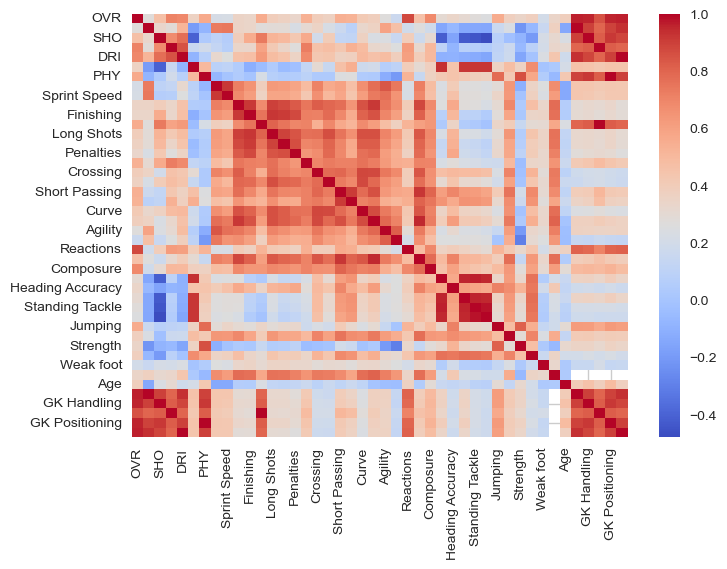

In [9]:
# definís columnas a excluir
cols_excluir = ['Unnamed: 0', 'Unnamed: 0.1', 'Rank']

# filtrás las numéricas quitando esas
cols_filtradas = [c for c in columnas_numericas if c not in cols_excluir]

# heatmap
sns.heatmap(
    df[cols_filtradas].corr(),
    annot=False,
    cmap='coolwarm'
)

In [10]:
# filtramos columnas que NO contienen 'GK'
cols_sin_GK = [c for c in cols_filtradas if 'GK' not in c]

# calculamos la matriz de correlación
corr_matrix = df[cols_sin_GK].corr()

# definimos el umbral
threshold = 0.85

# buscamos pares de columnas muy correlacionadas
high_corr_pairs = []

for i in range(len(corr_matrix.columns)):
    for j in range(i):
        if abs(corr_matrix.iloc[i, j]) > threshold:
            colname_i = corr_matrix.columns[i]
            colname_j = corr_matrix.columns[j]
            corr_value = corr_matrix.iloc[i, j]
            high_corr_pairs.append((colname_i, colname_j, corr_value))

# convertimos a DataFrame para verlo ordenado
high_corr_df = pd.DataFrame(high_corr_pairs, columns=['Var1', 'Var2', 'Correlation']).sort_values(
    by='Correlation', ascending=False
)

np.where(high_corr_df.Var1 == 'GK Diving') # busco cuales variables están altamente correlacionadas con GK Diving

# construimos un grafo que muestra variables correlacionadas
G = nx.Graph()
for idx, row in high_corr_df.iterrows():
    G.add_edge(row['Var1'], row['Var2'])

# obtener componentes conectadas (grupos de variables correlacionadas)
grupos = list(nx.connected_components(G))

# mostrar grupos
for i, g in enumerate(grupos):
    print(f"Grupo {i+1}: {sorted(g)}")

Grupo 1: ['DEF', 'Def Awareness', 'Interceptions', 'Sliding Tackle', 'Standing Tackle']
Grupo 2: ['Ball Control', 'Crossing', 'Curve', 'Dribbling', 'Finishing', 'Free Kick Accuracy', 'Long Passing', 'Long Shots', 'Penalties', 'Positioning', 'Short Passing', 'Volleys']
Grupo 3: ['Acceleration', 'Sprint Speed']
Grupo 4: ['OVR', 'Reactions']
Grupo 5: ['PHY', 'Strength']
Grupo 6: ['DRI', 'PAS']


Ahondaremos en el grupo 2 que es el más grande. Vemos que se puede dividir entre variables relacionadas a los pases y variables relacionadas con la finalización de la jugada.

In [11]:
grupos[1]
grupos = [grupos[0], grupos[2]] # saco el grupo 2 original y los ultimos tres

grupo2_1 = ['Ball Control', 'Crossing', 'Curve', 'Dribbling','Long Passing',
 'Long Shots','Positioning', 'Short Passing',] #mas relacionadas con el pase

grupo2_2 = ['Finishing','Free Kick Accuracy',
            'Penalties','Positioning','Volleys'] #mas relacionadas con la finalización de la jugada

# Notar que algunas se repiten en ambos subgrupos (Ball Control y Positioning)

grupos.append(set(grupo2_1))
grupos.append(set(grupo2_2))
grupos

[{'DEF',
  'Def Awareness',
  'Interceptions',
  'Sliding Tackle',
  'Standing Tackle'},
 {'Acceleration', 'Sprint Speed'},
 {'Ball Control',
  'Crossing',
  'Curve',
  'Dribbling',
  'Long Passing',
  'Long Shots',
  'Positioning',
  'Short Passing'},
 {'Finishing', 'Free Kick Accuracy', 'Penalties', 'Positioning', 'Volleys'}]

In [12]:
# nombres personalizados
nombres_grupos = ['DEF_grup', 'VEL_grup', 'PAS_grup', 'FIN_grup']

# crear diccionario
grupos_dict = {nombre: g for nombre, g in zip(nombres_grupos, grupos)}

# mostrar resultado
for nombre, columnas in grupos_dict.items():
    print(f'{nombre}: {sorted(columnas)}')

DEF_grup: ['DEF', 'Def Awareness', 'Interceptions', 'Sliding Tackle', 'Standing Tackle']
VEL_grup: ['Acceleration', 'Sprint Speed']
PAS_grup: ['Ball Control', 'Crossing', 'Curve', 'Dribbling', 'Long Passing', 'Long Shots', 'Positioning', 'Short Passing']
FIN_grup: ['Finishing', 'Free Kick Accuracy', 'Penalties', 'Positioning', 'Volleys']


### 1.5.Visualización de las variables en pairplots

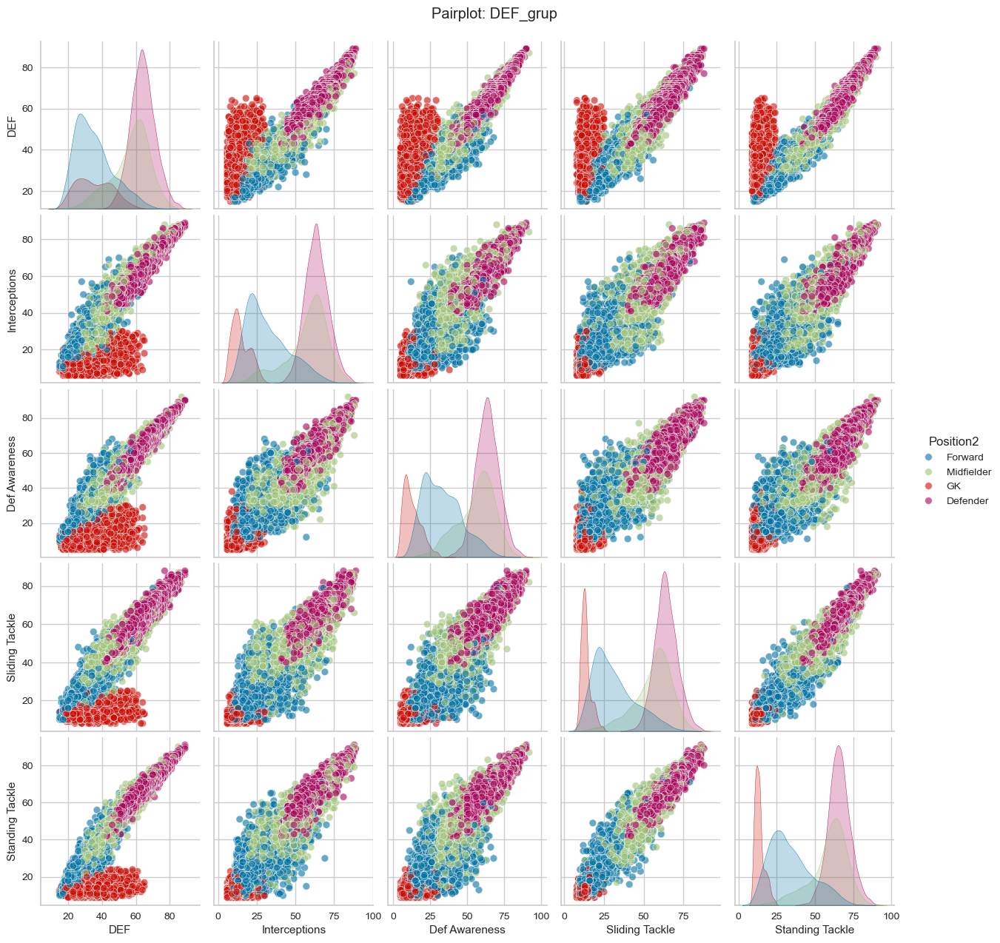

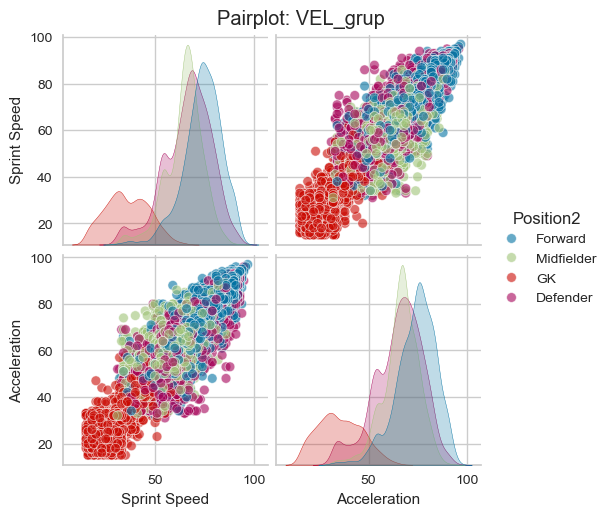

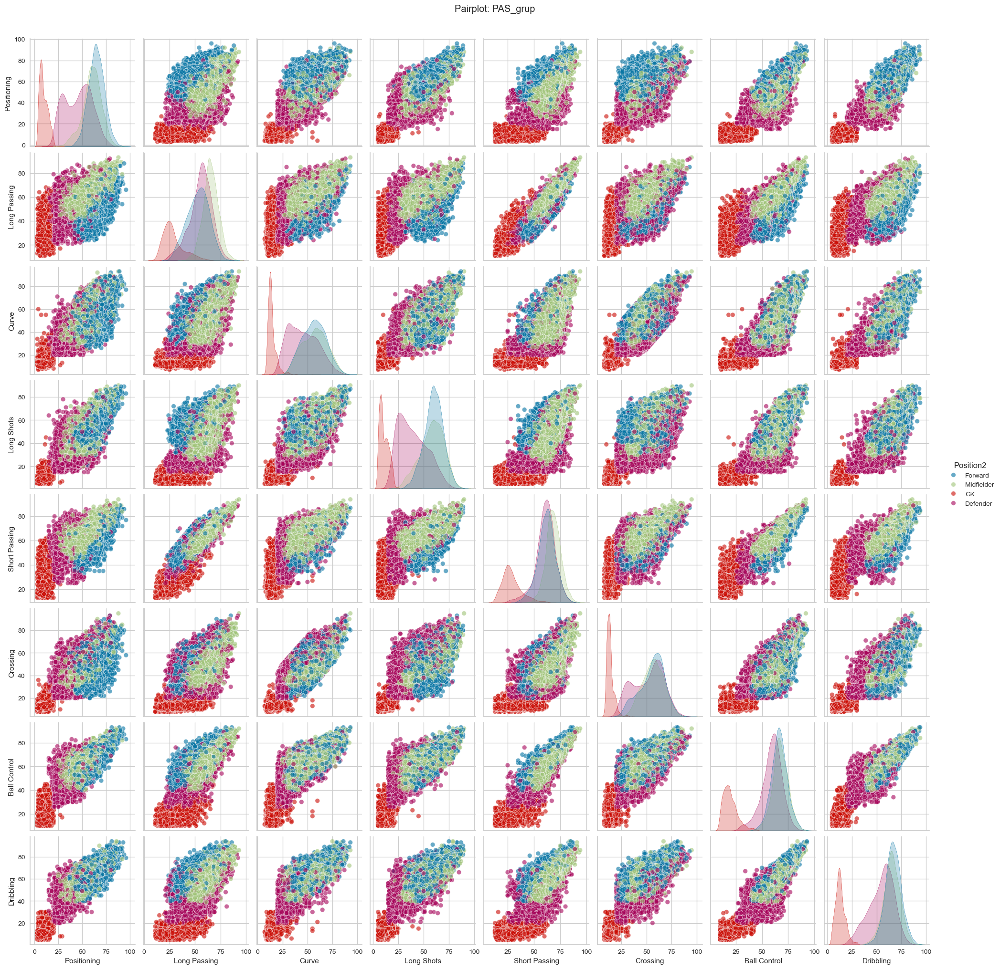

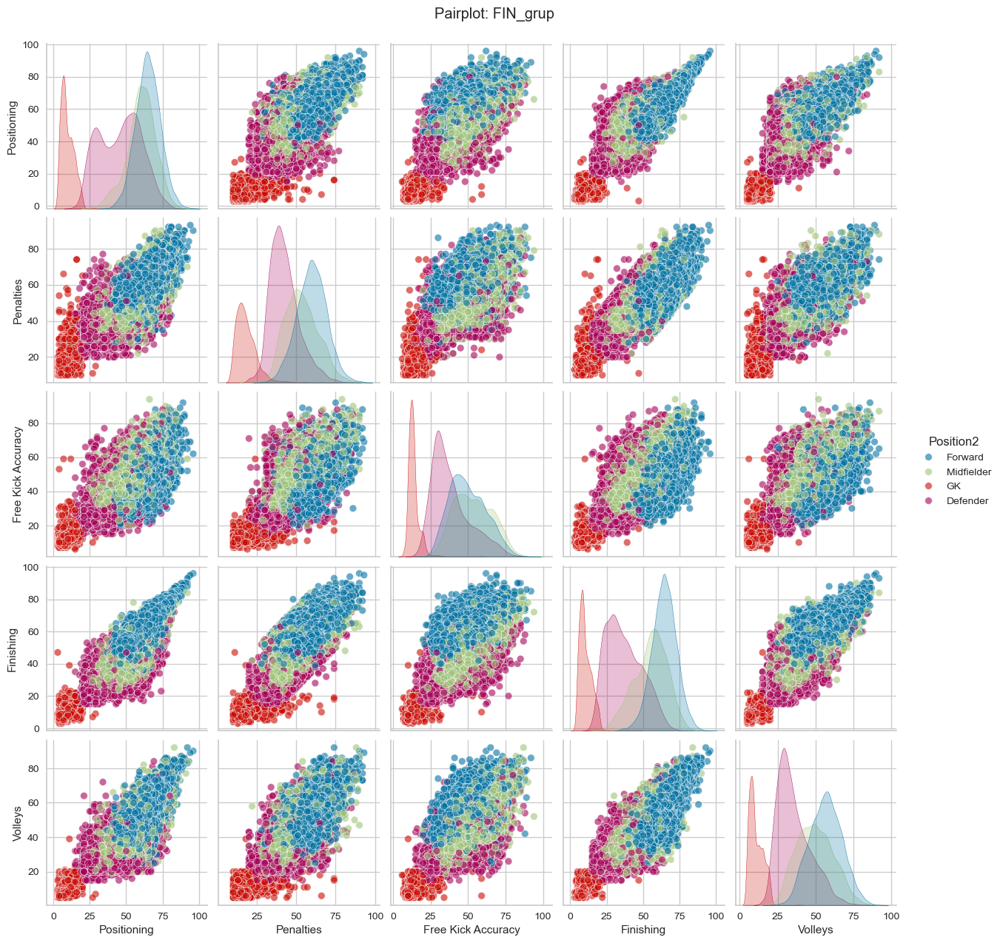

In [13]:
# Pairplots para cada grupo de variables correlacionadas
for nombre_grupo, columnas in grupos_dict.items():
    columnas_validas = [c for c in columnas if c in df.columns] + ['Position2']
    if len(columnas_validas) < 2:
        continue  # se necesita al menos 2 variables para pairplot
    sns.pairplot(df[columnas_validas], diag_kind='kde', plot_kws={'alpha':0.6}, hue='Position2')
    plt.suptitle(f'Pairplot: {nombre_grupo}', y=1.02)
    plt.show()

In [14]:
# seleccionar solo columnas numéricas
cols_numericas = df.select_dtypes(include='number').columns.tolist()

# eliminar columnas innecesarias y las que contienen 'GK'
cols_numericas = [c for c in cols_numericas if not c.startswith('Unnamed') and c != 'Rank' and 'GK' not in c]

# copiar df
df_reducido = df.copy()

# lista para acumular todas las columnas que forman parte de algún grupo
columnas_en_grupo = []

# recorrer grupos y crear columnas de media
for nombre_grupo, columnas in grupos_dict.items():
    # quedarnos solo con columnas válidas: numéricas y no GK
    columnas_validas = [c for c in columnas if c in cols_numericas]
    if len(columnas_validas) == 0:
        continue
    # acumular para filtrar después
    columnas_en_grupo.extend(columnas_validas)
    # calcular la media por fila
    df_reducido[nombre_grupo] = df_reducido[columnas_validas].mean(axis=1)

# eliminar duplicados de columnas_en_grupo
columnas_en_grupo = list(set(columnas_en_grupo))

# columnas numéricas que quedaron fuera de los grupos
columnas_fuera_grupo = [c for c in cols_numericas if c not in columnas_en_grupo]

# dataframe final con columnas de grupos + columnas numéricas fuera de grupos
df_final = df_reducido[list(grupos_dict.keys()) + columnas_fuera_grupo]

# mostrar primeras filas
print(df_final.head())

   DEF_grup  VEL_grup  PAS_grup  FIN_grup  OVR  PAC  SHO  PAS  DRI  PHY  \
0      33.2      97.0    84.500      84.8   91   97   90   80   92   78   
1      86.4      65.5    85.625      69.4   91   66   80   86   84   85   
2      40.4      87.0    77.375      86.8   91   88   92   70   81   88   
3      78.6      80.5    84.000      80.0   90   80   87   83   88   83   
4      26.0      95.0    84.125      76.4   90   95   84   81   91   69   

   Shot Power  Vision  Agility  Balance  Reactions  Composure  \
0          90      83       93       82         93         88   
1          92      84       66       67         93         94   
2          94      74       77       69         94         87   
3          85      90       82       79         91         87   
4          81      85       94       84         86         83   

   Heading Accuracy  Jumping  Stamina  Strength  Aggression  Weak foot  \
0                73       88       88        77          64          4   
1         

In [15]:
df_final

,DEF_grup,VEL_grup,PAS_grup,FIN_grup,OVR,PAC,SHO,PAS,DRI,PHY,Shot Power,Vision,Agility,Balance,Reactions,Composure,Heading Accuracy,Jumping,Stamina,Strength,Aggression,Weak foot,Skill moves,Age,Height_cm,Weight_kg
0,33.2,97.0,84.500,84.8,91,97,90,80,92,78,90,83,93,82,93,88,73,88,88,77,64,4,5,25,182.0,75.0
1,86.4,65.5,85.625,69.4,91,66,80,86,84,85,92,84,66,67,93,94,81,83,91,83,85,4,3,28,191.0,82.0
2,40.4,87.0,77.375,86.8,91,88,92,70,81,88,94,74,77,69,94,87,83,92,76,93,88,3,3,24,195.0,94.0
3,78.6,80.5,84.000,80.0,90,80,87,83,88,83,85,90,82,79,91,87,75,84,93,77,85,4,4,21,186.0,75.0
4,26.0,95.0,84.125,76.4,90,95,84,81,91,69,81,85,94,84,86,83,50,74,84,65,58,4,5,24,176.0,73.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16156,33.8,31.5,46.250,39.0,47,31,45,47,52,45,48,55,64,68,32,53,37,27,65,36,47,3,2,21,169.0,62.0
16157,40.2,66.5,42.250,38.4,47,67,38,46,45,55,50,43,59,71,46,36,47,49,56,53,59,3,2,23,176.0,74.0
16158,42.2,57.0,42.625,41.8,47,57,47,38,50,49,44,45,60,66,48,46,50,53,51,57,24,3,2,22,181.0,69.0
16159,41.6,66.0,43.875,36.6,47,66,35,46,46,64,52,41,54,59,46,39,49,60,65,68,54,3,2,19,187.0,71.0


## 2.Clustering

### 2.1. K-Means

In [88]:
cols_excluir_cluster = ['Rank', 'Unnamed: 0.1', 'Unnamed: 0', 'Wage', 'Name', 'url', 'Height', 'Weight']  

# usar df_final en lugar de df
cols_cluster = [c for c in df_final.select_dtypes(include='number').columns if c not in cols_excluir_cluster]

print(f"Variables seleccionadas para clusterización: {len(cols_cluster)}")
print("Variables incluidas:", cols_cluster)

df_final = df_final.fillna(0)
X = df_final[cols_cluster]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Variables seleccionadas para clusterización: 29
Variables incluidas: ['DEF_grup', 'VEL_grup', 'PAS_grup', 'FIN_grup', 'OVR', 'PAC', 'SHO', 'PAS', 'DRI', 'PHY', 'Shot Power', 'Vision', 'Agility', 'Balance', 'Reactions', 'Composure', 'Heading Accuracy', 'Jumping', 'Stamina', 'Strength', 'Aggression', 'Weak foot', 'Skill moves', 'Age', 'Height_cm', 'Weight_kg', 'cluster', 'cluster_db_no_scaling', 'cluster_db_scaling']


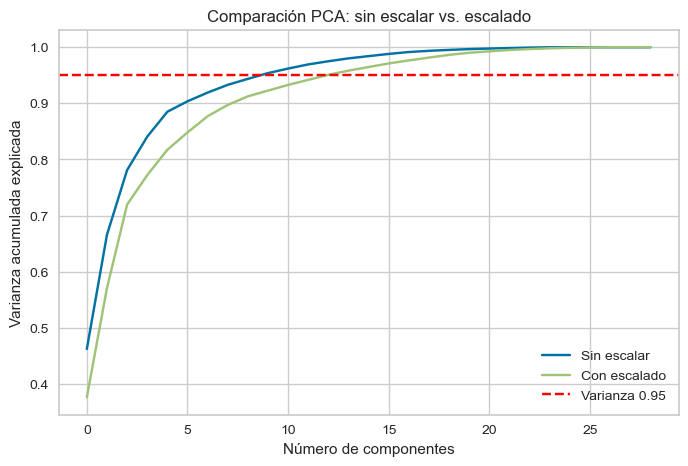

In [89]:
# PCA on unscaled data
pca_no_scaled = PCA()
pca_no_scaled.fit(X)
explained_var_no_scaled = np.cumsum(pca_no_scaled.explained_variance_ratio_)

# PCA on scaled data
pca_scaled = PCA()
pca_scaled.fit(X_scaled)
explained_var_scaled = np.cumsum(pca_scaled.explained_variance_ratio_)

plt.figure(figsize=(8,5))
plt.plot(explained_var_no_scaled, label='Sin escalar')
plt.plot(explained_var_scaled, label='Con escalado')
plt.xlabel('Número de componentes')
plt.ylabel('Varianza acumulada explicada')
plt.title('Comparación PCA: sin escalar vs. escalado')
plt.grid(True)
plt.axhline(0.95, color='red', linestyle='--', label='Varianza 0.95')
plt.legend()

plt.show()

In [90]:
def dim_reduction(x):
    dim_reduce = PCA(n_components=25) #dim reduction
    dim_reduce_fit = dim_reduce.fit_transform(x)
    return dim_reduce, dim_reduce_fit

dim_reduce, dim_reduce_fit = dim_reduction(X)

dim_reduce_scaled, dim_reduce_fit_scaled = dim_reduction(X_scaled)

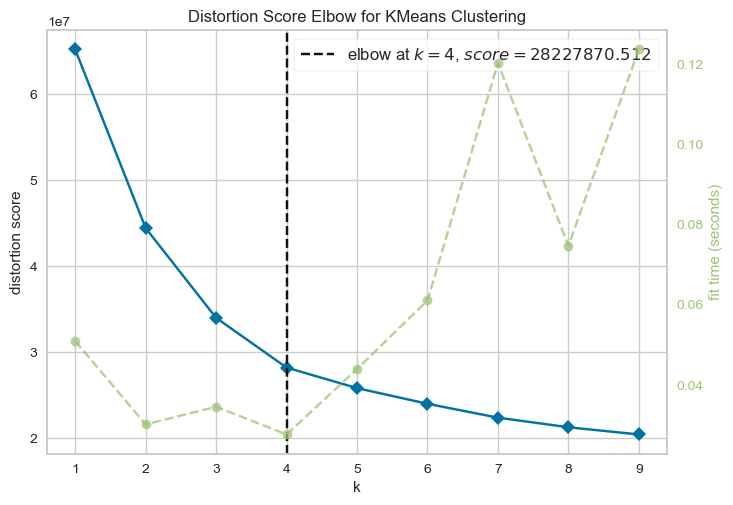

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [91]:
model = KMeans()
fig = KElbowVisualizer(model,k=(1,10))
fig.fit(dim_reduce_fit)
fig.show()

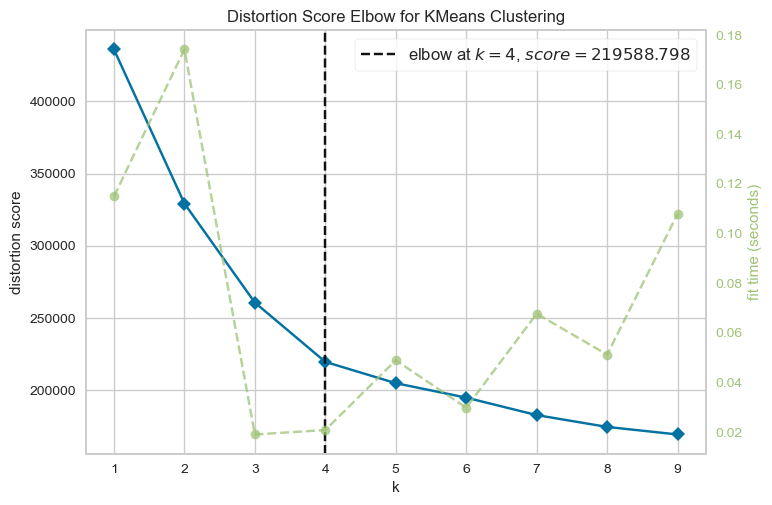

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [92]:
model = KMeans()
fig = KElbowVisualizer(model,k=(1,10))
fig.fit(dim_reduce_fit_scaled)
fig.show()

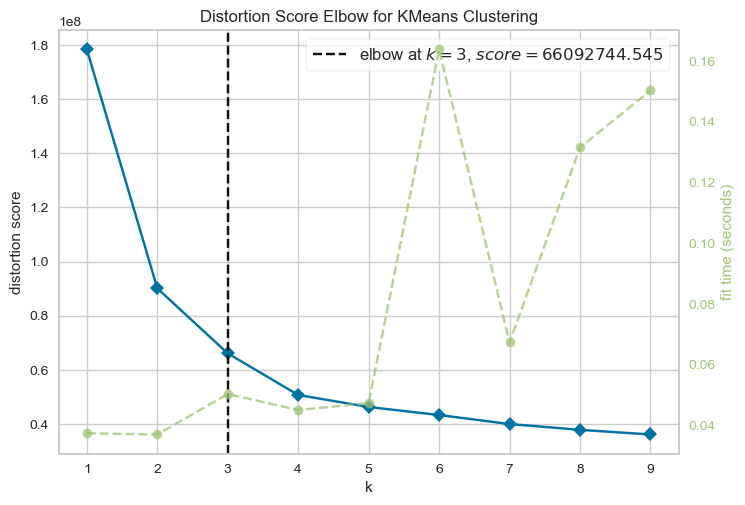

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [21]:
model = KMeans()
fig = KElbowVisualizer(model,k=(1,10))
fig.fit(X)
fig.show()

El distortion score mas bajo es el que usa xscaled asi que se continuará con ese.

In [93]:
def cluster_and_visualize(dataset, df_base, title='', n_clusters=3):
    kmeans = KMeans(n_clusters=n_clusters, init='k-means++', random_state=1)
    y_kmeans = kmeans.fit_predict(dataset)

    # trabajar sobre copia del df_final
    df_vis = df_base.copy()
    df_vis['y_kmeans'] = y_kmeans
    df_vis['xs'] = dataset[:,0]
    df_vis['ys'] = dataset[:,1]

    # scatterplot
    g = sns.relplot(
        x='xs', y='ys',
        hue='y_kmeans',
        palette='bright',
        kind='scatter',
        style='Position2',
        data=df_vis,
        alpha=0.7
    )

    # evaluar el modelo
    score = metrics.silhouette_score(dataset, y_kmeans)

    plt.title(f'KMeans Clustering {title}')
    plt.gcf().text(
        0.78, 0.05,
        f'Silhouette Score: {score:.3f}',
        fontsize=12, color='black',
        bbox=dict(facecolor='white', alpha=0.7)
    )
    plt.show()

    # heatmap de distribución
    sns.heatmap(
        pd.crosstab(df_vis['Position2'], df_vis['y_kmeans'], normalize='index'),
        annot=True, cmap='Blues'
    )

    return df_vis

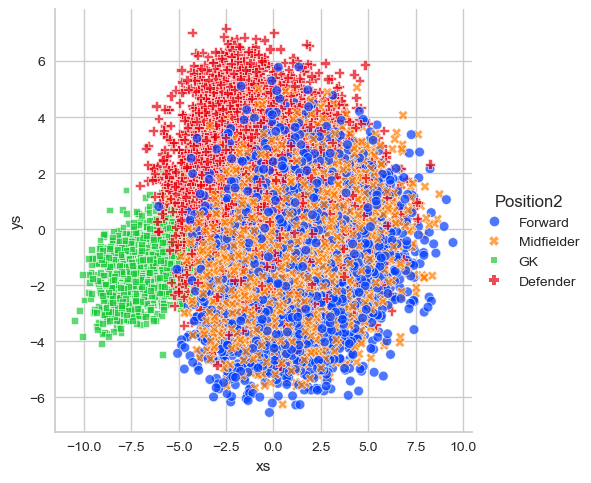

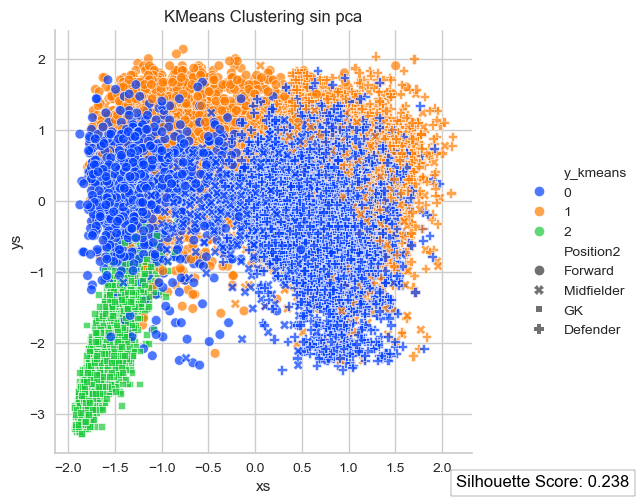

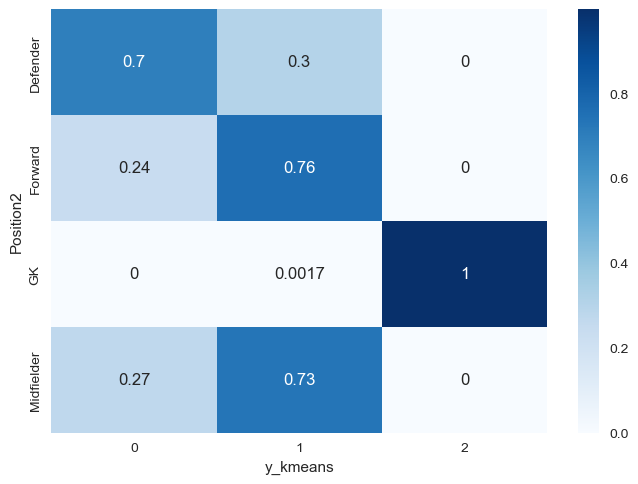

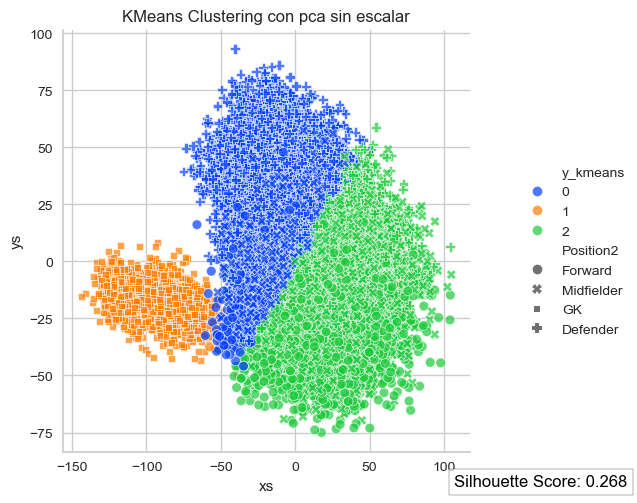

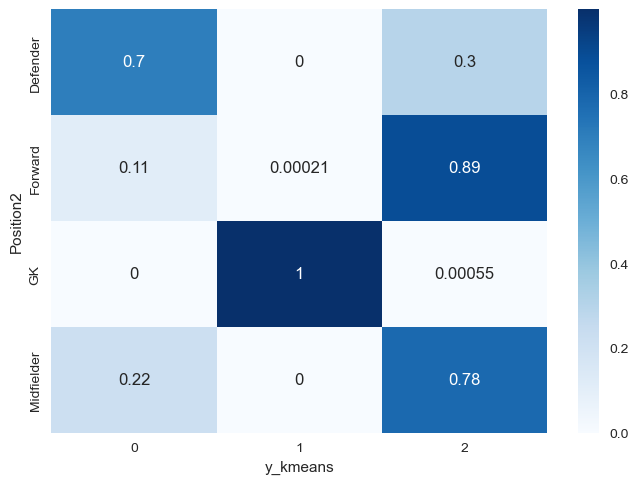

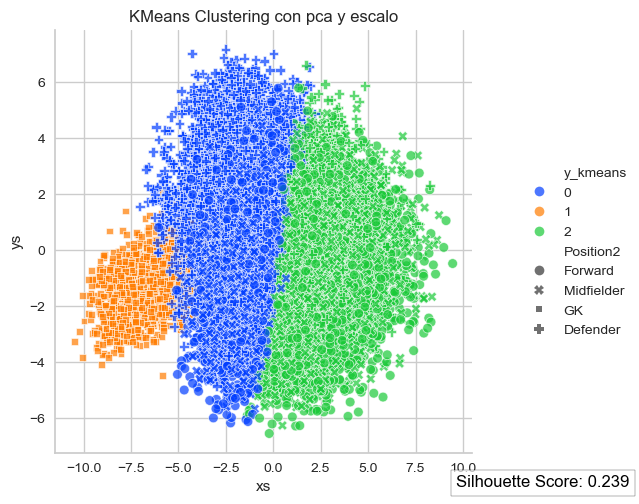

,Unnamed: 0.1,Unnamed: 0,Rank,Name,OVR,PAC,SHO,PAS,DRI,DEF,PHY,Acceleration,Sprint Speed,Positioning,Finishing,Shot Power,Long Shots,Volleys,Penalties,Vision,Crossing,Free Kick Accuracy,Short Passing,Long Passing,Curve,Dribbling,Agility,Balance,Reactions,Ball Control,Composure,Interceptions,Heading Accuracy,Def Awareness,Standing Tackle,Sliding Tackle,Jumping,Stamina,Strength,Aggression,Position,Weak foot,Skill moves,Preferred foot,Height,Weight,Alternative positions,Age,Nation,League,Team,play style,url,GK Diving,GK Handling,GK Kicking,GK Positioning,GK Reflexes,Height_cm,Weight_kg,Position2,xs,ys,y_kmeans
0,0,0,1,Kylian Mbappé,91,97,90,80,92,36,78,97,97,93,94,90,83,84,84,83,78,69,86,71,80,93,93,82,93,92,88,38,73,26,34,32,88,88,77,64,ST,4,5,Right,"182cm / 6'0""",75kg / 165lb,LW,25,France,LALIGA EA SPORTS,Real Madrid,"Quick Step+, Acrobatic, Finesse Shot, Flair, R...",https://www.ea.com/games/ea-sports-fc/ratings/...,0.0,0.0,0.0,0.0,0.0,182.0,75.0,Forward,9.454951,-0.479633,2
1,1,1,2,Rodri,91,66,80,86,84,87,85,65,66,76,74,92,89,71,62,84,76,64,93,91,86,84,66,67,93,90,94,84,81,92,87,82,83,91,83,85,CDM,4,3,Right,"191cm / 6'3""",82kg / 181lb,CM,28,Spain,Premier League,Manchester City,"Tiki Taka+, Aerial, Bruiser, Long Ball Pass, P...",https://www.ea.com/games/ea-sports-fc/ratings/...,0.0,0.0,0.0,0.0,0.0,191.0,82.0,Midfielder,7.616127,3.375396,2
2,2,2,4,Erling Haaland,91,88,92,70,81,45,88,80,94,96,96,94,83,90,90,74,58,62,77,66,77,79,77,69,94,83,87,43,83,38,47,29,92,76,93,88,ST,3,3,Left,"195cm / 6'5""",94kg / 207lb,0,24,Norway,Premier League,Manchester City,"Acrobatic+, Bruiser, Power Header, Power Shot,...",https://www.ea.com/games/ea-sports-fc/ratings/...,0.0,0.0,0.0,0.0,0.0,195.0,94.0,Forward,7.254283,3.372568,2
3,3,3,5,Jude Bellingham,90,80,87,83,88,78,83,81,80,91,90,85,86,77,74,90,66,68,89,89,73,89,82,79,91,89,87,82,75,77,79,77,84,93,77,85,CAM,4,4,Right,"186cm / 6'1""",75kg / 165lb,CM,21,England,LALIGA EA SPORTS,Real Madrid,"Relentless+, Flair, Intercept, Slide Tackle, T...",https://www.ea.com/games/ea-sports-fc/ratings/...,0.0,0.0,0.0,0.0,0.0,186.0,75.0,Midfielder,8.740860,1.244424,2
4,4,4,7,Vini Jr.,90,95,84,81,91,29,69,95,95,87,89,81,83,73,71,85,81,62,83,77,79,93,94,84,86,90,83,26,50,32,25,18,74,84,65,58,LW,4,5,Right,"176cm / 5'9""",73kg / 161lb,"ST, LM",24,Brazil,LALIGA EA SPORTS,Real Madrid,"Quick Step+, Chip Shot, Finesse Shot, First To...",https://www.ea.com/games/ea-sports-fc/ratings/...,0.0,0.0,0.0,0.0,0.0,176.0,73.0,Forward,8.197598,-2.425844,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16156,16156,16156,17717,Engson Singh,47,31,45,47,52,34,45,32,31,39,44,48,50,25,43,55,38,44,45,51,46,51,64,68,32,50,53,23,37,33,39,40,27,65,36,47,CAM,3,2,Right,"169cm / 5'7""",62kg / 137lb,CM,21,India,ISL,Mohun Bagan SG,0,https://www.ea.com/games/ea-sports-fc/ratings/...,0.0,0.0,0.0,0.0,0.0,169.0,62.0,Midfielder,-4.243919,-3.790498,0
16157,16157,16157,17717,Ousmane Sylla,47,67,38,46,45,40,55,66,67,47,34,50,33,32,40,43,35,39,54,56,30,41,59,71,46,42,36,37,47,36,41,47,49,56,53,59,CM,3,2,Right,"176cm / 5'9""",74kg / 163lb,0,23,Senegal,MLS,Houston Dynamo,0,https://www.ea.com/games/ea-sports-fc/ratings/...,0.0,0.0,0.0,0.0,0.0,176.0,74.0,Midfielder,-3.512195,-1.648127,0
16158,16158,16158,17717,Wei Feng,47,57,47,38,50,43,49,55,59,50,47,44,50,32,51,45,38,29,37,33,36,49,60,66,48,48,46,41,50,43,42,42,53,51,57,24,RB,3,2,Right,"181cm / 5'11""",69kg / 152lb,0,22,China PR,CSL,Changchun Yatai,0,https://www.ea.com/games/ea-sports-fc/ratings/...,0.0,0.0,0.0,0.0,0.0,181.0,69.0,Defender,-3.989687,-1.902600,0
16159,16159,16159,17717,Won Hui Do,47,66,35,46,46,41,64,69,63,45,24,52,39,33,42,41,39,39,52,55,33,45,54,59,46,43,39,42,49,34,42,49,60,65,68,54,CM,3,2,Right,"187cm / 6'2""",71kg / 157lb,0,19,Korea Republic,K League 1,Jeju United,0,https://w

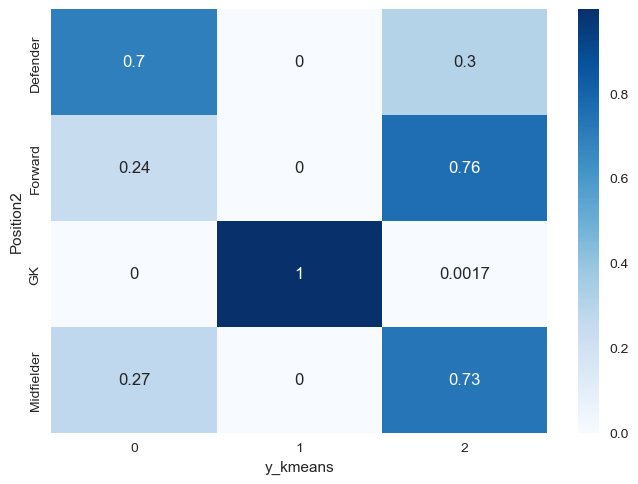

In [97]:
# coords PCA 2D para graficar
xs = dim_reduce_fit_scaled[:, 0]
ys = dim_reduce_fit_scaled[:, 1]

# asegurar que Position2 esté en df_plot
df_plot = df_final.copy()
df_plot['Position2'] = df['Position2'].values  # la traemos del df original
df_plot['xs'] = xs
df_plot['ys'] = ys

# scatter base con posiciones
g = sns.relplot(
    x='xs',
    y='ys',
    hue="Position2",
    palette='bright',
    kind="scatter",
    style='Position2',
    data=df_plot,
    alpha=0.7
)
plt.show()

# Clustering en distintas variantes
cluster_and_visualize(X_scaled, df, title='sin pca')
cluster_and_visualize(dim_reduce_fit, df, title='con pca sin escalar')
cluster_and_visualize(dim_reduce_fit_scaled, df, title='con pca y escalo')

Al hacer tres grupos los defensores quedan agrupados en el grupo 0 pero se mezclan delanteros y mediocampistas en el grupo 1. 

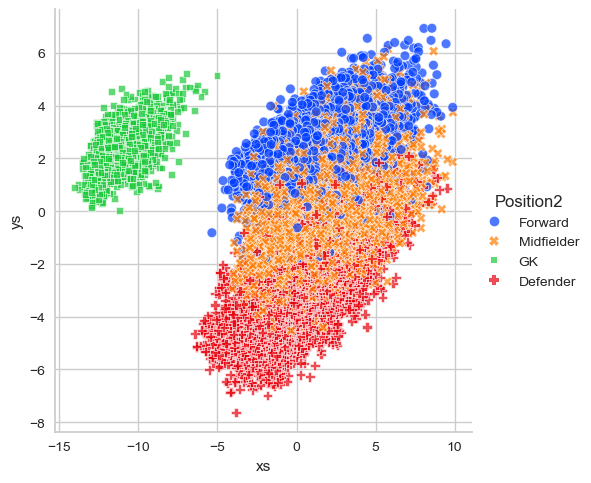

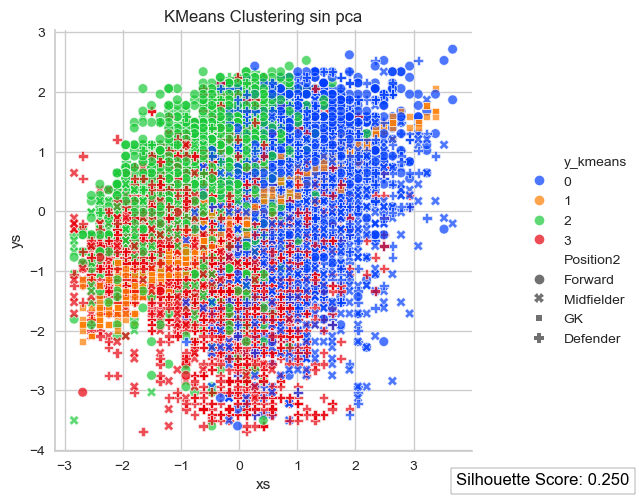

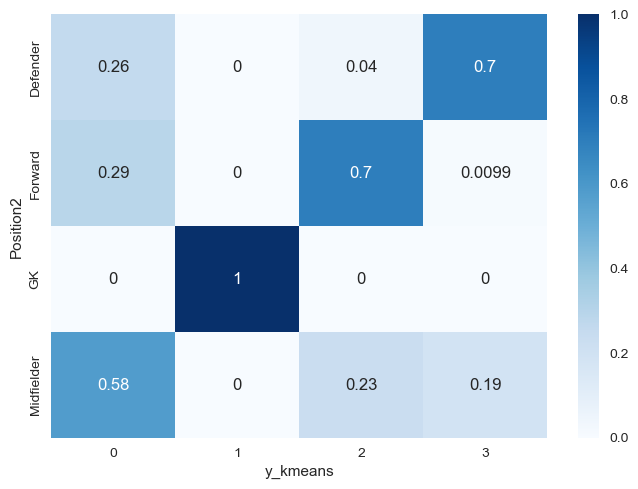

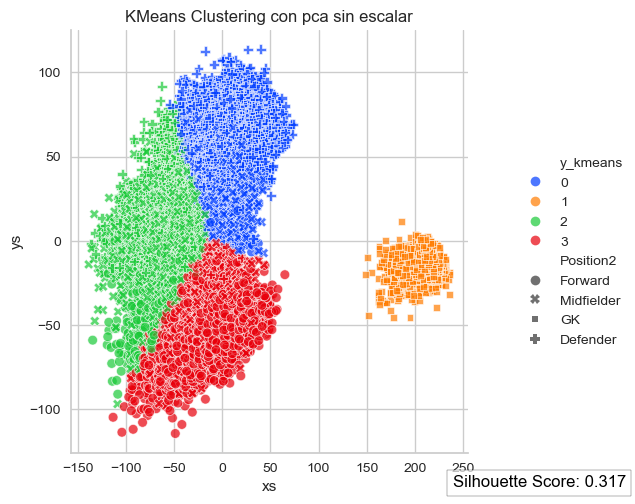

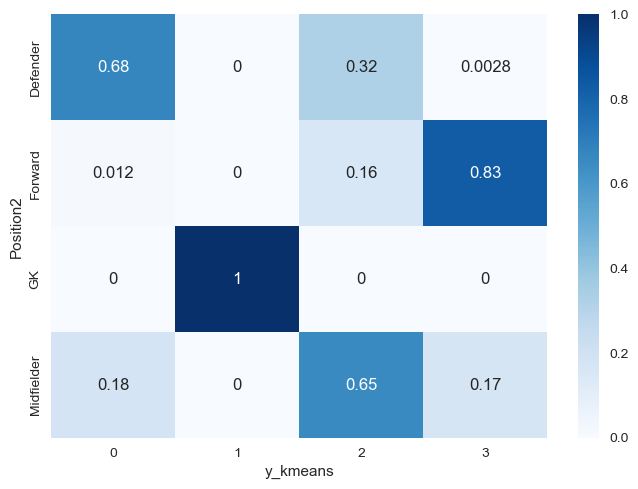

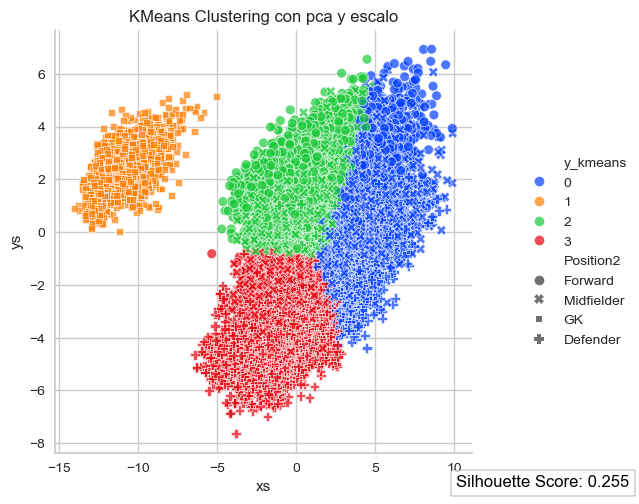

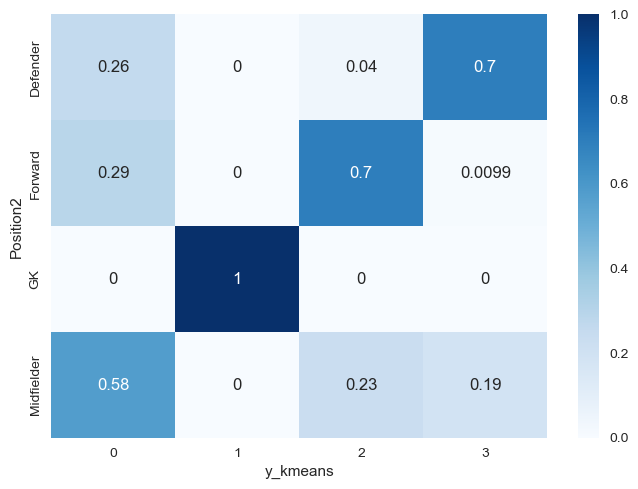

In [24]:
# ploteamos primero por posicion sin clusterizar en las variables definidas por pca
# con x escalado
xs = dim_reduce_fit_scaled[:,0]
ys = dim_reduce_fit_scaled[:,1]
df['xs'] = xs
df['ys'] = ys

g = sns.relplot(
    x='xs',
    y='ys',
    hue="Position2",
    palette='bright',
    kind="scatter",
    style='Position2',
    data=df,
    alpha=0.7
)

plt.show()


n_clusters=4
cluster_and_visualize(X_scaled, title= 'sin pca', n_clusters=n_clusters)
cluster_and_visualize(dim_reduce_fit, title= 'con pca sin escalar', n_clusters=n_clusters)
cluster_and_visualize(dim_reduce_fit_scaled, title= 'con pca y escalo', n_clusters=n_clusters)

Clasifica mejor sin escalear. Siempre se logra identificar a los arqueros pero al modelo le cuesta más identificar entre los otros grupos. De todas formas, es posible que los mediocampistas que son la posición más dispersa entre grupos varíen en sus habilidades.

In [98]:
app = dash.Dash(__name__)

# df ya definido
num_cols = ['Rank', 'OVR', 'PAC', 'SHO', 'PAS', 'DRI',
       'DEF', 'PHY', 'Acceleration', 'Sprint Speed', 'Positioning',
       'Finishing', 'Shot Power', 'Long Shots', 'Volleys', 'Penalties',
       'Vision', 'Crossing', 'Free Kick Accuracy', 'Short Passing',
       'Long Passing', 'Curve', 'Dribbling', 'Agility', 'Balance', 'Reactions',
       'Ball Control', 'Composure', 'Interceptions', 'Heading Accuracy',
       'Def Awareness', 'Standing Tackle', 'Sliding Tackle', 'Jumping',
       'Stamina', 'Strength', 'Aggression', 'Weak foot', 'Skill moves', 'Age',
       'GK Diving', 'GK Handling', 'GK Kicking', 'GK Positioning',
       'GK Reflexes', 'Height_cm', 'Weight_kg']  # ejemplo

app.layout = html.Div([
    dcc.Dropdown(
        id='num_var',
        options=[{'label': c, 'value': c} for c in num_cols],
        value='Height_cm'
    ),
    dcc.Checklist(
        id='position_filter',
        options=[{'label': c, 'value': c} for c in df['y_kmeans'].unique()],
        value=list(df['y_kmeans'].unique()),  # todas seleccionadas
        inline=True
    ),
    dcc.Graph(id='hist_graph')
])

@app.callback(
    dash.dependencies.Output('hist_graph', 'figure'),
    [dash.dependencies.Input('num_var', 'value'),
     dash.dependencies.Input('position_filter', 'value')]
)
def update_histogram(num_var, selected_positions):
    filtered = df[df['y_kmeans'].isin(selected_positions)]
    fig = px.histogram(
        filtered,
        x=num_var,
        color='y_kmeans',
        barmode='overlay',
        opacity=0.6,
        nbins=30,
        histnorm='probability density'  # normaliza el histograma
    )
    return fig

if __name__ == '__main__':
    app.run(debug=True, port=8054)

### 2.2. Gaussian Mixture Model

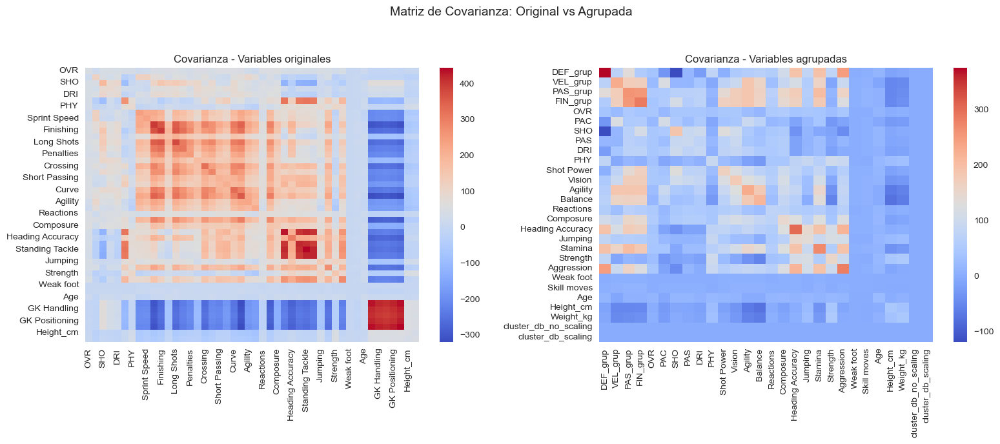

In [99]:
# Matrices de covarianza
df_cov = df[num_cols].drop(columns=["Rank"]).cov()
df_grup_cov = df_final.drop(columns=["cluster"], errors="ignore").cov()

# Figura con 2 subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.heatmap(df_cov, annot=False, cmap='coolwarm', ax=axes[0])
axes[0].set_title("Covarianza - Variables originales")

sns.heatmap(df_grup_cov, annot=False, cmap='coolwarm', ax=axes[1])
axes[1].set_title("Covarianza - Variables agrupadas")

plt.suptitle('Matriz de Covarianza: Original vs Agrupada', fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

A primera vista, no queda muy claro qué tipo de matriz de covarianza se está utilizando:

- **Full:** es una opción posible, pero se observan valores con covarianza muy baja.
- **Tied:** parece ser la más adecuada, ya que muestra una mezcla de covarianzas nulas y altas.

Para determinar cuál es la más apropiada, se realiza un análisis de los parámetros **BIC** y **AIC**.


- **AIC (Akaike Information Criterion):** mide la calidad del modelo penalizando la complejidad. Modelos con menor AIC son preferibles, ya que explican bien los datos sin sobreajustarse.  
- **BIC (Bayesian Information Criterion):** es similar al AIC, pero penaliza la complejidad del modelo más fuertemente, favoreciendo modelos más simples. Al igual que con AIC, valores menores indican un mejor balance entre ajuste y simplicidad.

In [100]:
# Variables numéricas agrupadas
X_grupo = df_final.select_dtypes(include='number').dropna()

# GMM con distintas matrices de covarianza
for cov in ["full", "tied", "diag", "spherical"]:
    gmm = GaussianMixture(n_components=3, covariance_type=cov, random_state=0)
    gmm.fit(X_grupo)
    print(cov, "BIC:", gmm.bic(X_grupo), "AIC:", gmm.aic(X_grupo))

full BIC: 1625775.415131721 AIC: 1615055.058573101
tied BIC: 1844734.3722971412 AIC: 1840704.6256423946
diag BIC: 2273744.2760897637 AIC: 2272390.7733965665
spherical BIC: 3365818.257883107 AIC: 3365110.745111663


Resulta lo que se había planteado: la matriz de covarianza es tipo TIED

In [37]:
# Entrenar GMM en datos agrupados
gmm = GaussianMixture(n_components=3, covariance_type="tied", random_state=0)
gmm.fit(X_grupo)
labels_grupo = gmm.predict(X_grupo)
df_final.loc[X_grupo.index, "cluster"] = labels_grupo

# PCA a 2D
pca = PCA(n_components=2)
X_pca_grupo = pca.fit_transform(X_grupo)

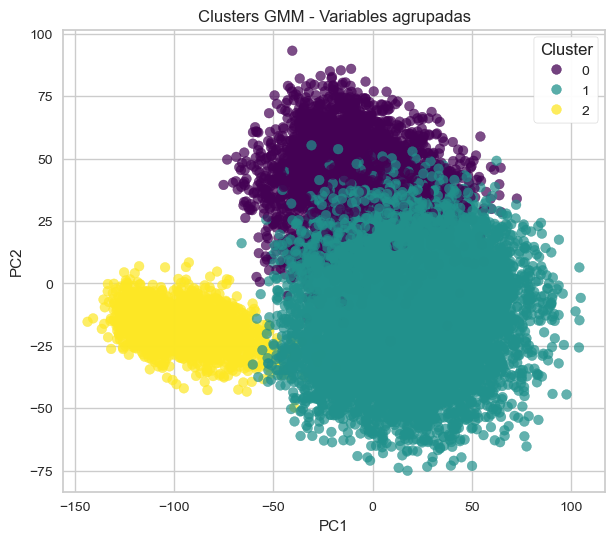

In [105]:
fig, ax = plt.subplots(figsize=(7,6))

scatter = ax.scatter(
    X_pca_grupo[:,0], X_pca_grupo[:,1],
    c=labels_grupo, cmap="viridis", alpha=0.7
)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Clusters GMM - Variables agrupadas")

legend = ax.legend(*scatter.legend_elements(), title="Cluster", loc="best", frameon=True)
ax.add_artist(legend)

plt.show()



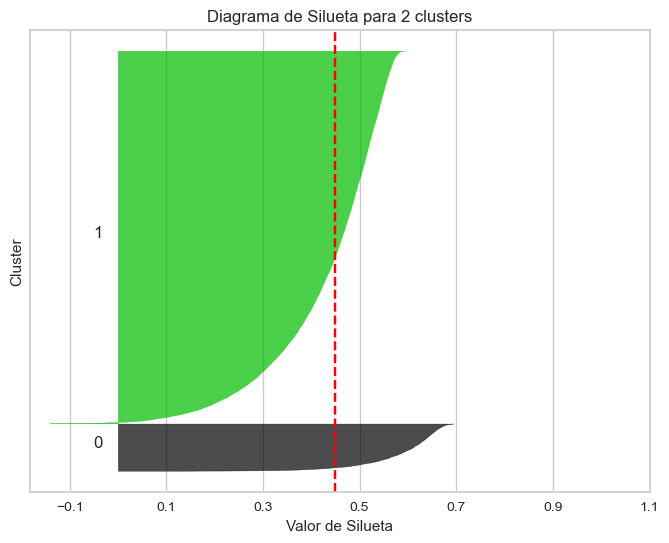

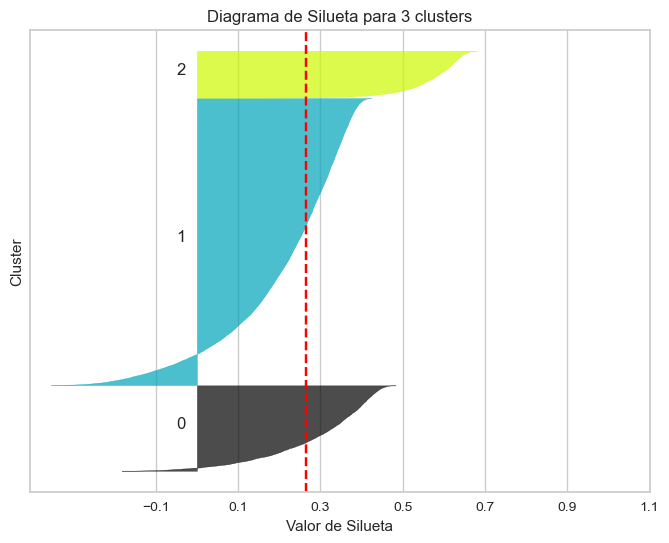

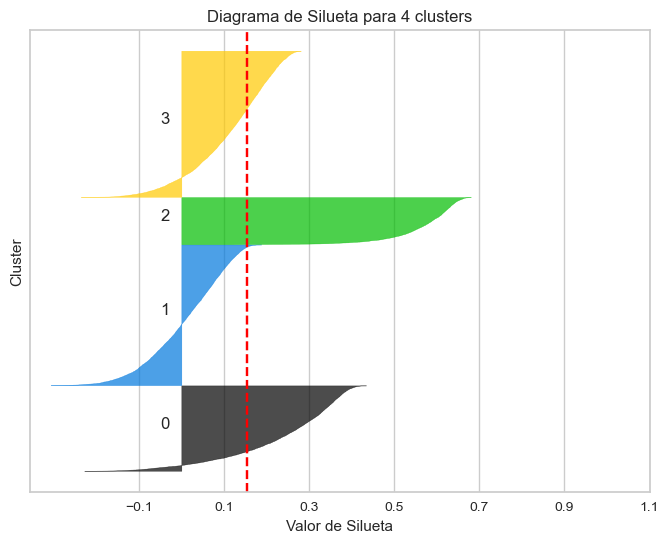

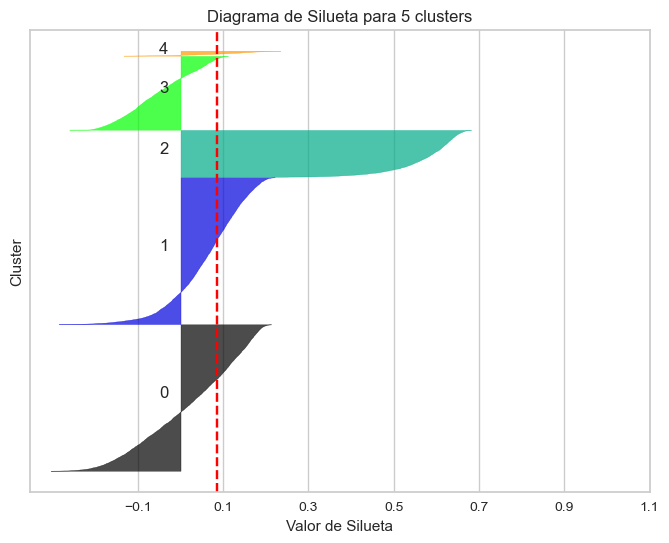

In [54]:
X = X_grupo.values
silhouette_avgs = []

for n_clusters in range(2, 6):  # arranca en 2 porque con 1 no se puede
    gmm = GaussianMixture(n_components=n_clusters, random_state=42)
    gmm.fit(X)
    labels = gmm.predict(X)
    
    silhouette_avg = silhouette_score(X, labels)
    silhouette_avgs.append(silhouette_avg)
    
    sample_silhouette_values = silhouette_samples(X, labels)
    
    fig, ax1 = plt.subplots(figsize=(8, 6))
    y_lower = 10
    for i in range(n_clusters):
        ith = sample_silhouette_values[labels == i]
        ith.sort()
        size_cluster_i = ith.shape[0]
        y_upper = y_lower + size_cluster_i
        color = plt.cm.nipy_spectral(float(i) / n_clusters)
        ax1.fill_betweenx(np.arange(y_lower, y_upper), 0, ith,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
        y_lower = y_upper + 10
    
    ax1.set_title(f"Diagrama de Silueta para {n_clusters} clusters")
    ax1.set_xlabel("Valor de Silueta")
    ax1.set_ylabel("Cluster")
    ax1.axvline(x=silhouette_avg, color="red", linestyle="--")
    ax1.set_yticks([])
    ax1.set_xticks(np.arange(-0.1, 1.1, 0.2))
    plt.show()


El gráfico de siluetas indica que, aunque la mejor opción según el índice parece ser **2 clusters**, esta elección resulta poco satisfactoria en términos de separación de los datos. 

Por otro lado, **3 clusters** ofrece una silueta más representativa, y proporciona una mejor estructura de agrupamiento, incluso considerando algunos datos que quedan mal asignados.


In [106]:
cov_types = ['full', 'tied', 'diag', 'spherical']
n_clusters_list = range(1, 6)

bic_dict = {cov: [] for cov in cov_types}

for cov in cov_types:
    for n in n_clusters_list:
        gmm = GaussianMixture(n_components=n, covariance_type=cov, random_state=42)
        gmm.fit(X_grupo)
        bic_dict[cov].append(gmm.bic(X_grupo))


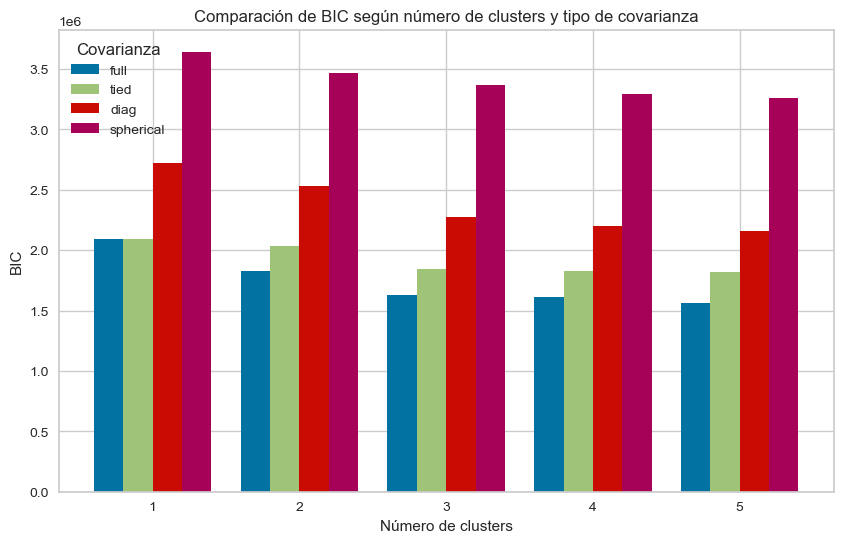

In [107]:
x = np.arange(len(n_clusters_list))
width = 0.2

plt.figure(figsize=(10,6))
for i, cov in enumerate(cov_types):
    plt.bar(x + i*width, bic_dict[cov], width=width, label=cov)

plt.xlabel("Número de clusters")
plt.ylabel("BIC")
plt.title("Comparación de BIC según número de clusters y tipo de covarianza")
plt.xticks(x + width*1.5, n_clusters_list)
plt.legend(title="Covarianza")
plt.show()

### 2.3. Mean Shift

In [118]:
# Seleccionar variables numéricas de df_final (ya agrupadas)
X_ms = df_final.select_dtypes(include='number').fillna(0)

# Escalar datos
scaler = StandardScaler()
X_ms_scaled = scaler.fit_transform(X_ms)

print("Dimensiones del dataset para Mean Shift:", X_ms_scaled.shape)

Dimensiones del dataset para Mean Shift: (16161, 31)


In [119]:
# Estimar bandwidth automáticamente
bandwidth_auto = estimate_bandwidth(X_ms_scaled, quantile=0.2, n_samples=500, random_state=42)
ms_auto = MeanShift(bandwidth=bandwidth_auto, bin_seeding=True)
labels_auto = ms_auto.fit_predict(X_ms_scaled)

print("Clusters encontrados (sin PCA, auto bandwidth):", len(np.unique(labels_auto)))

Clusters encontrados (sin PCA, auto bandwidth): 1


In [123]:
# Reducir dimensionalidad con PCA (10 componentes)
pca = PCA(n_components=10, random_state=42)
X_pca_ms = pca.fit_transform(X_ms_scaled)

# Mean Shift con bandwidth ajustado manualmente
bandwidth = 3.5
ms_final = MeanShift(bandwidth=bandwidth, bin_seeding=True)
labels_ms = ms_final.fit_predict(X_pca_ms)

df_final["cluster_ms"] = labels_ms

print("Clusters encontrados con PCA (bandwidth=3.5):", len(np.unique(labels_ms)))
print("Distribución de jugadores por cluster:")
print(pd.Series(labels_ms).value_counts())



Clusters encontrados con PCA (bandwidth=3.5): 5
Distribución de jugadores por cluster:
0    10292
1     3542
2     1814
4      423
3       90
Name: count, dtype: int64


In [124]:
# Reducir dimensionalidad
pca = PCA(n_components=10, random_state=42)
X_pca_ms = pca.fit_transform(X_ms_scaled)

# Bandwidth más chico manual
bandwidth = 1.5
ms = MeanShift(bandwidth=bandwidth, bin_seeding=True)
ms_labels_pca = ms.fit_predict(X_pca_ms)

print("Número de clusters encontrados:", len(np.unique(ms_labels_pca)))
print("Distribución de jugadores por cluster:")
print(pd.Series(ms_labels_pca).value_counts())

Número de clusters encontrados: 1798
Distribución de jugadores por cluster:
0       323
1       293
5       258
3       248
6       235
       ... 
1165      1
1133      1
987       1
1570      1
1680      1
Name: count, Length: 1798, dtype: int64


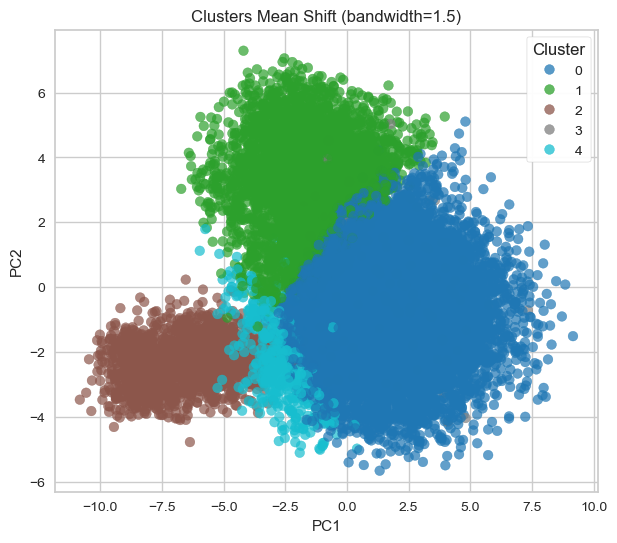

In [125]:
# PCA 2D solo para graficar
pca2 = PCA(n_components=2, random_state=42)
X_pca2_ms = pca2.fit_transform(X_ms_scaled)

# Scatter
fig, ax = plt.subplots(figsize=(7,6))
scatter = ax.scatter(
    X_pca2_ms[:,0], X_pca2_ms[:,1],
    c=labels_ms, cmap="tab10", alpha=0.7
)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title(f"Clusters Mean Shift (bandwidth={bandwidth})")

# Leyenda
legend = ax.legend(*scatter.legend_elements(), title="Cluster", loc="best", frameon=True)
ax.add_artist(legend)

plt.show()

In [128]:
score_ms = silhouette_score(X_ms_scaled, labels_ms)
print(f"Silhouette Score (Mean Shift, bandwidth=3.5): {score_ms:.3f}")

Silhouette Score (Mean Shift, bandwidth=3.5): 0.226


El análisis con **Mean Shift** muestra que:

- Con el parámetro automático (`estimate_bandwidth`), el modelo colapsa en un único cluster, lo que no resulta útil.  
- Ajustando manualmente `bandwidth=3.5` y aplicando PCA (10 componentes), el modelo detecta **5 clusters**, aunque con tamaños muy desiguales:  
  - Un cluster dominante con más de 10.000 jugadores.  
  - Dos medianos de 3.500 y 1.800 jugadores.  
  - Dos pequeños (423 y 90 jugadores).  
- El **Silhouette Score fue 0.226**, lo que refleja una separación débil entre los grupos, significativamente menor a la observada en KMeans y GMM.  
- Los **arqueros** se separan relativamente bien, pero mediocampistas y delanteros aparecen mezclados, lo que sugiere que Mean Shift no logra capturar de manera clara la estructura de este dataset.  

En conclusión, aunque Mean Shift tiene la ventaja de no requerir definir el número de clusters de antemano, en este caso necesita un ajuste manual de `bandwidth` y produce resultados menos interpretab


### 2.3. DBScan

In [131]:
# Escalar datos
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(df_final)

# Reducir dimensionalidad (10 componentes para clustering)
pca = PCA(n_components=10, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("Dimensiones después de PCA:", X_pca.shape)

Dimensiones después de PCA: (16161, 10)


In [132]:
eps_values = [0.5, 1.0, 1.5, 2.0]
min_samples_values = [5, 10, 20, 50]

results = []
for eps in eps_values:
    for min_samples in min_samples_values:
        db = DBSCAN(eps=eps, min_samples=min_samples)
        labels = db.fit_predict(X_pca)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)
        results.append((eps, min_samples, n_clusters, n_noise))

results_df = pd.DataFrame(results, columns=["eps","min_samples","n_clusters","n_noise"])
results_df

,eps,min_samples,n_clusters,n_noise
0,0.5,5,7,22
1,0.5,10,6,51
2,0.5,20,6,73
3,0.5,50,4,134
4,1.0,5,1,0
5,1.0,10,1,0
6,1.0,20,1,0
7,1.0,50,1,0
8,1.5,5,1,0
9,1.5,10,1,0


In [133]:
# Mejor combinación: eps=0.5, min_samples=50
db = DBSCAN(eps=0.5, min_samples=50)
clusters_db = db.fit_predict(X_pca)

# Guardar en df_final
df_final["cluster_db"] = clusters_db

print("Clusters detectados:", len(set(clusters_db)) - (1 if -1 in clusters_db else 0))
print("Ruido detectado:", list(clusters_db).count(-1))

Clusters detectados: 4
Ruido detectado: 134


In [134]:
pd.Series(clusters_db).value_counts()

 0    10570
 1     3258
 2     1814
 3      385
-1      134
Name: count, dtype: int64

In [135]:
mask = clusters_db != -1
X_valid = X_pca[mask]
labels_valid = clusters_db[mask]

sil = silhouette_score(X_valid, labels_valid)
dbi = davies_bouldin_score(X_valid, labels_valid)

print(f"Silhouette Score: {sil:.3f}")
print(f"Davies-Bouldin Index: {dbi:.3f}")

Silhouette Score: 0.386
Davies-Bouldin Index: 0.886


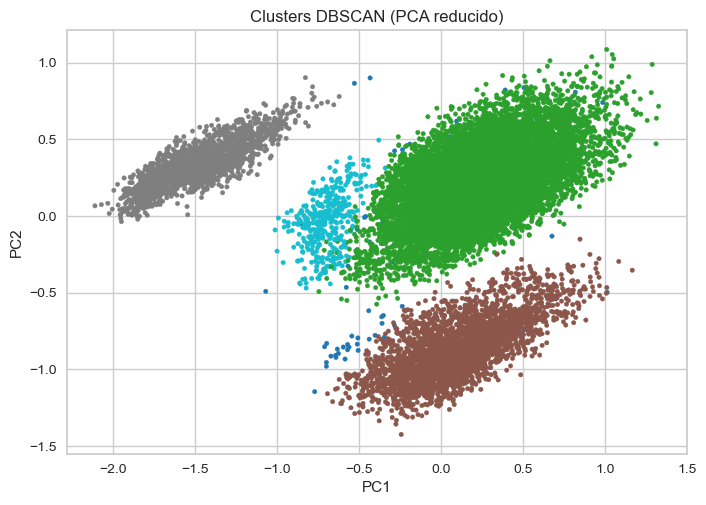

In [136]:
# Reducir a 2 componentes para graficar
pca2 = PCA(n_components=2, random_state=42)
X_pca2 = pca2.fit_transform(X_scaled)

plt.scatter(X_pca2[:,0], X_pca2[:,1], c=clusters_db, cmap="tab10", s=10)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Clusters DBSCAN (PCA reducido)")
plt.show()

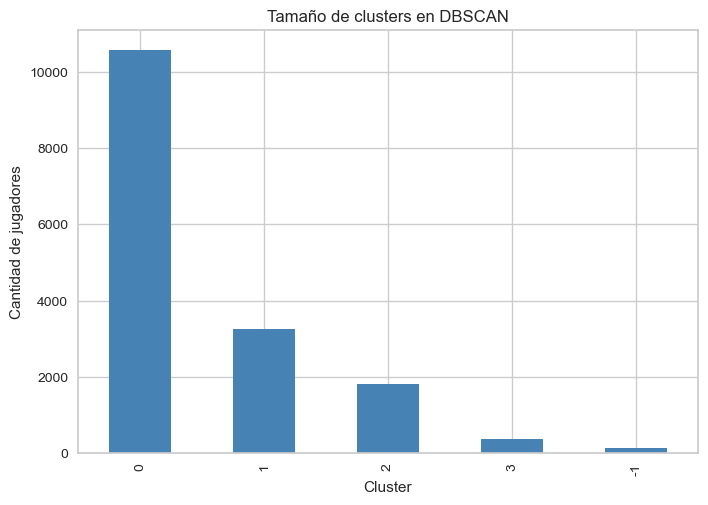

In [137]:
cluster_sizes = pd.Series(clusters_db).value_counts()
cluster_sizes.plot(kind="bar", color="steelblue")
plt.xlabel("Cluster")
plt.ylabel("Cantidad de jugadores")
plt.title("Tamaño de clusters en DBSCAN")
plt.show()

El análisis con **DBSCAN** muestra que:

- Con **MinMaxScaler + PCA** y parámetros `eps=0.5`, `min_samples=50` se detectan **2 clusters principales y un grupo de ruido**.  
- El **Silhouette Score fue 0.386** y el **Davies-Bouldin Index fue 0.886**, lo que indica que la calidad de separación de los grupos es **moderada y claramente inferior a KMeans y GMM**.  
- En el heatmap se observa que los **arqueros** forman un grupo diferenciado, mientras que mediocampistas y delanteros quedan mezclados.  
- Aunque DBSCAN no requiere fijar el número de clusters, en este dataset fue muy sensible a los parámetros y no alcanzó resultados tan sólidos como los otros métodos de clustering.  

### 2.4.Clusterización Jerárquica

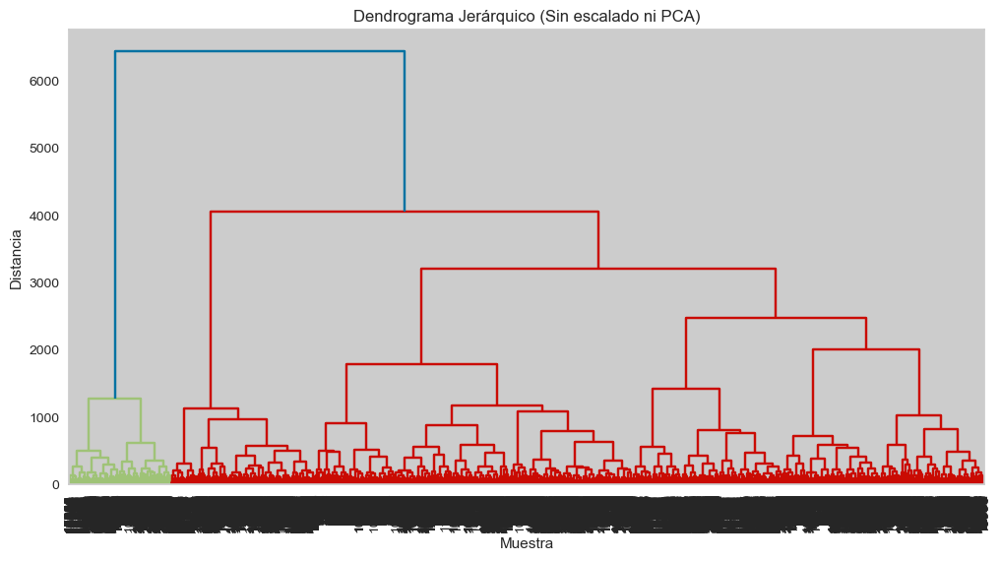

In [140]:
# Linkage con método ward (minimiza varianza intra-cluster)
Z_raw = linkage(df_final, method='ward')

# Dendrograma
plt.figure(figsize=(12, 6))
dendrogram(Z_raw, leaf_rotation=90, leaf_font_size=10)
plt.title("Dendrograma Jerárquico (Sin escalado ni PCA)")
plt.xlabel("Muestra")
plt.ylabel("Distancia")
plt.show()

# Cortar en 3 clusters (como sugiere dendrograma)
clusters_raw = fcluster(Z_raw, 3, criterion='maxclust')


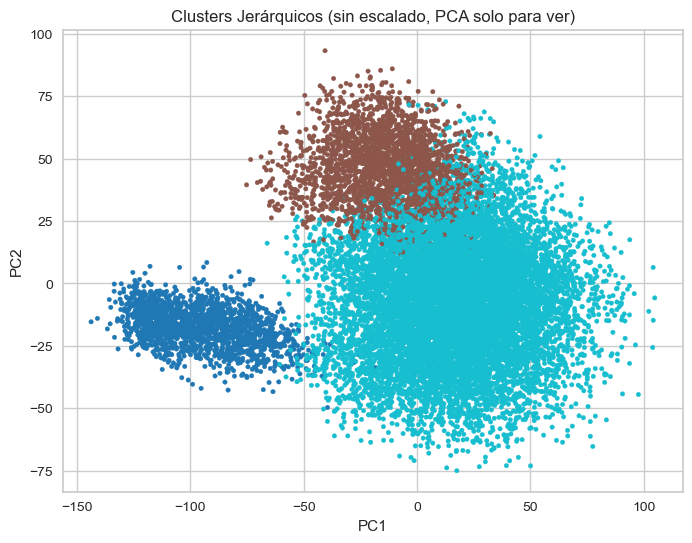

In [141]:
pca_vis = PCA(n_components=2, random_state=42)
X_pca_raw = pca_vis.fit_transform(df_final)

plt.figure(figsize=(8,6))
plt.scatter(X_pca_raw[:,0], X_pca_raw[:,1], c=clusters_raw, cmap="tab10", s=10)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Clusters Jerárquicos (sin escalado, PCA solo para ver)")
plt.show()


In [142]:
sil_raw = silhouette_score(df_final, clusters_raw)
dbi_raw = davies_bouldin_score(df_final, clusters_raw)
print(f"Silhouette Score (sin escalado): {sil_raw:.3f}")
print(f"Davies-Bouldin Index (sin escalado): {dbi_raw:.3f}")


Silhouette Score (sin escalado): 0.265
Davies-Bouldin Index (sin escalado): 1.146


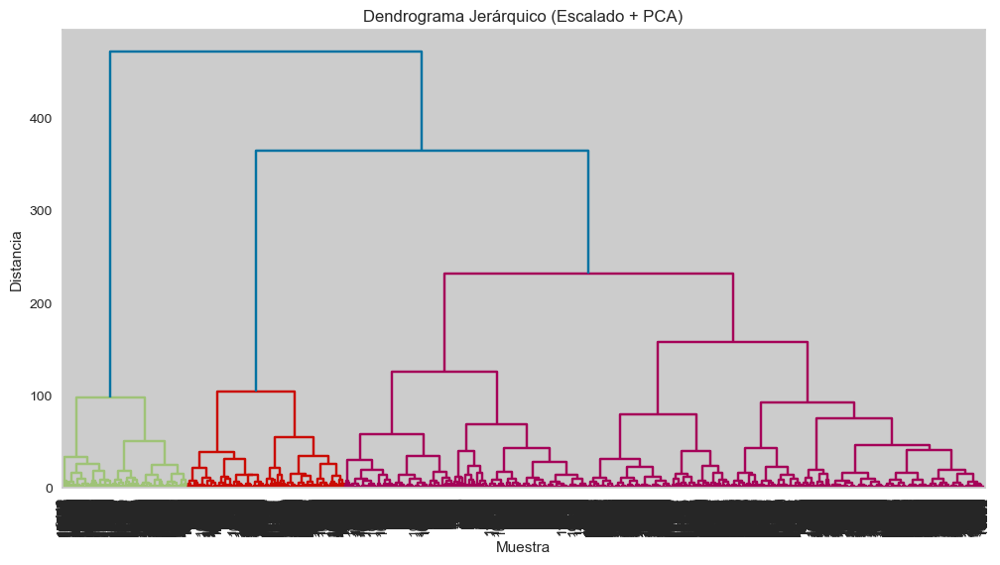

In [143]:
# Escalado
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_final)

# PCA reducción a 2D para clustering
pca = PCA(n_components=2, random_state=42)
X_pca_scaled = pca.fit_transform(X_scaled)

# Linkage y dendrograma
Z_scaled = linkage(X_pca_scaled, method='ward')
plt.figure(figsize=(12, 6))
dendrogram(Z_scaled, leaf_rotation=90, leaf_font_size=10)
plt.title("Dendrograma Jerárquico (Escalado + PCA)")
plt.xlabel("Muestra")
plt.ylabel("Distancia")
plt.show()

# Cortar en 4 clusters (como sugiere dendrograma)
clusters_scaled = fcluster(Z_scaled, 4, criterion='maxclust')


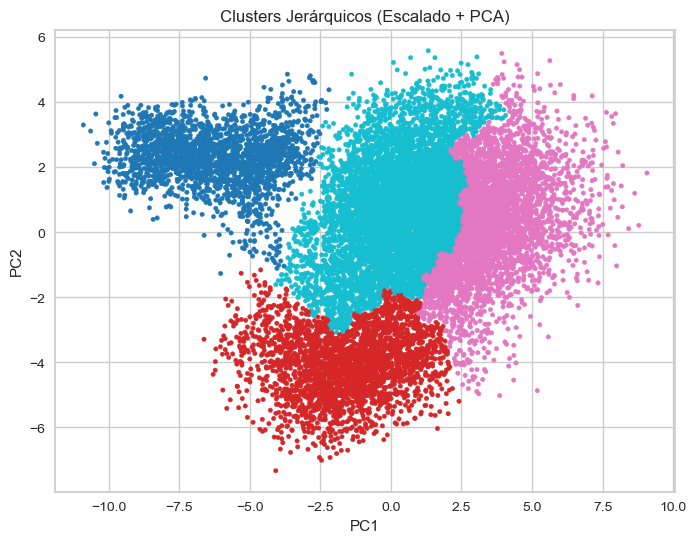

In [144]:
plt.figure(figsize=(8,6))
plt.scatter(X_pca_scaled[:,0], X_pca_scaled[:,1], c=clusters_scaled, cmap="tab10", s=10)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Clusters Jerárquicos (Escalado + PCA)")
plt.show()


In [145]:
sil_scaled = silhouette_score(X_scaled, clusters_scaled)
dbi_scaled = davies_bouldin_score(X_scaled, clusters_scaled)
print(f"Silhouette Score (escalado + PCA): {sil_scaled:.3f}")
print(f"Davies-Bouldin Index (escalado + PCA): {dbi_scaled:.3f}")


Silhouette Score (escalado + PCA): 0.200
Davies-Bouldin Index (escalado + PCA): 1.548


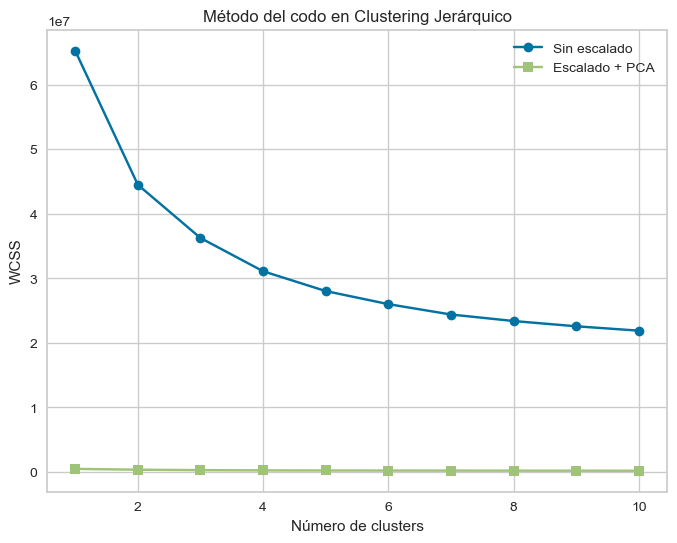

In [146]:
def compute_wcss(Z, X, max_clusters=10):
    wcss = []
    for k in range(1, max_clusters + 1):
        labels = fcluster(Z, k, criterion="maxclust") - 1
        cluster_ss = 0
        for i in range(k):
            cluster_points = X[labels == i]
            if len(cluster_points) > 0:
                centroid = cluster_points.mean(axis=0)
                cluster_ss += ((cluster_points - centroid) ** 2).sum()
        wcss.append(cluster_ss)
    return wcss

max_clusters = 10
wcss_raw = compute_wcss(Z_raw, df_final.values, max_clusters=max_clusters)
wcss_scaled = compute_wcss(Z_scaled, X_scaled, max_clusters=max_clusters)

plt.figure(figsize=(8,6))
plt.plot(range(1, max_clusters + 1), wcss_raw, 'o-', label='Sin escalado')
plt.plot(range(1, max_clusters + 1), wcss_scaled, 's-', label='Escalado + PCA')
plt.xlabel("Número de clusters")
plt.ylabel("WCSS")
plt.title("Método del codo en Clustering Jerárquico")
plt.legend()
plt.grid(True)
plt.show()


**Conclusiones Clustering Jerárquico**

- **Sin escalado ni PCA**:  
  - Dendrograma sugiere 3 clusters principales.  
  - **Silhouette = 0.265**, **DBI = 1.146** → separación débil, pero más clara que en la variante con escalado.  
  - Los clusters aparecen algo más compactos y consistentes.

- **Con escalado + PCA**:  
  - Dendrograma sugiere 4 clusters.  
  - **Silhouette = 0.200**, **DBI = 1.548** → peor calidad, mayor solapamiento entre grupos.  
  - El algoritmo fuerza un cluster minoritario que probablemente refleja outliers.

- **Comparación**:  
  - El método del codo sugiere 3 clusters sin escalado y 4 con escalado.  
  - Los valores de métrica y las visualizaciones muestran que el mejor desempeño se logra **sin escalado ni PCA**.  

En general, el clustering jerárquico ofrece una visión exploratoria útil, pero no supera en calidad a KMeans o GMM en este dataset.


## 3. Análisis por posición

Para el analisis por posición se utilizará el método K-Means

### 3.1. Defensores

In [149]:
# Filtrar defensores en df
df_filtered_defender = df[df['Position2'] == 'Defender'].copy()

# Merge con df_final para quedarnos con las features reducidas
df_filtered_defender = df_filtered_defender.merge(
    df_final,
    left_index=True,
    right_index=True,
    suffixes=('', '_final')
)

# Seleccionar solo columnas numéricas de df_final para clustering
cols_cluster_def = df_final.columns.tolist()

# Escalar
X_def = StandardScaler().fit_transform(df_filtered_defender[cols_cluster_def])

# PCA
pca_def = PCA(n_components=15, random_state=42)
dim_reduce_fit_defender = pca_def.fit_transform(X_def)




In [150]:
def cluster_and_visualize_filtered(complete_dataframe, dataset, title='', n_clusters=3):
    # KMeans
    kmeans = KMeans(n_clusters=n_clusters, init='k-means++', random_state=1)
    y_kmeans = kmeans.fit_predict(dataset)
    complete_dataframe['y_kmeans_specific'] = y_kmeans

    # Coordenadas para visualización (primeras dos componentes de PCA)
    xs = dataset[:, 0]
    ys = dataset[:, 1]
    complete_dataframe['xs'] = xs
    complete_dataframe['ys'] = ys

    # Silhouette
    sil_score = silhouette_score(dataset, y_kmeans)

    # Scatter interactivo
    fig = px.scatter(
        complete_dataframe,
        x='xs',
        y='ys',
        color='y_kmeans_specific',
        hover_data=['Name', 'Position', 'OVR', 'Team'],
    )
    fig.update_layout(
        title=f'KMeans Clustering {title}, Silhouette Score: {sil_score:.3f}',
        width=800,
        height=700
    )
    fig.show()

    return complete_dataframe


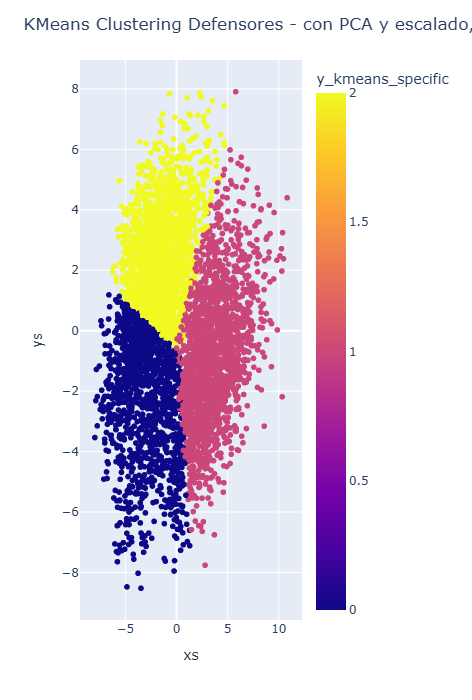

In [151]:
# Clustering y visualización para defensores
df_filtered_defender = cluster_and_visualize_filtered(
    df_filtered_defender,
    dim_reduce_fit_defender,
    title='Defensores - con PCA y escalado',
    n_clusters=3
)


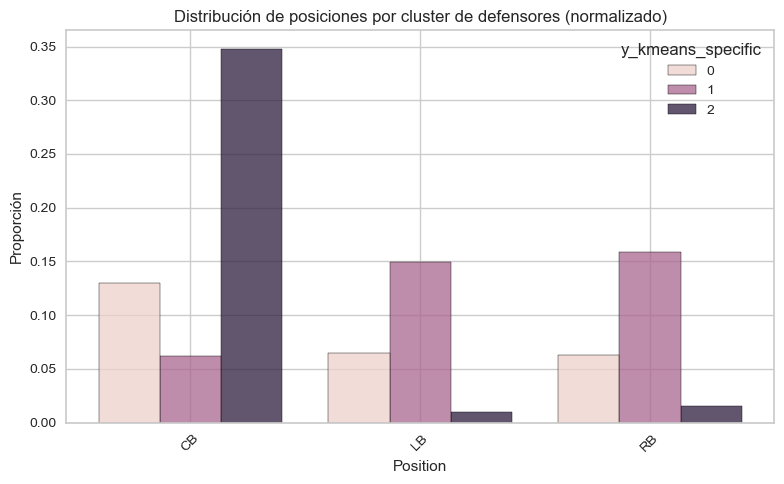

In [152]:
plt.figure(figsize=(8,5))
sns.histplot(
    data=df_filtered_defender,
    x='Position',
    hue='y_kmeans_specific',
    multiple='dodge',
    shrink=0.8,
    stat='probability',   # normaliza por posición
    discrete=True
)
plt.title('Distribución de posiciones por cluster de defensores (normalizado)')
plt.xlabel('Position')
plt.ylabel('Proporción')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


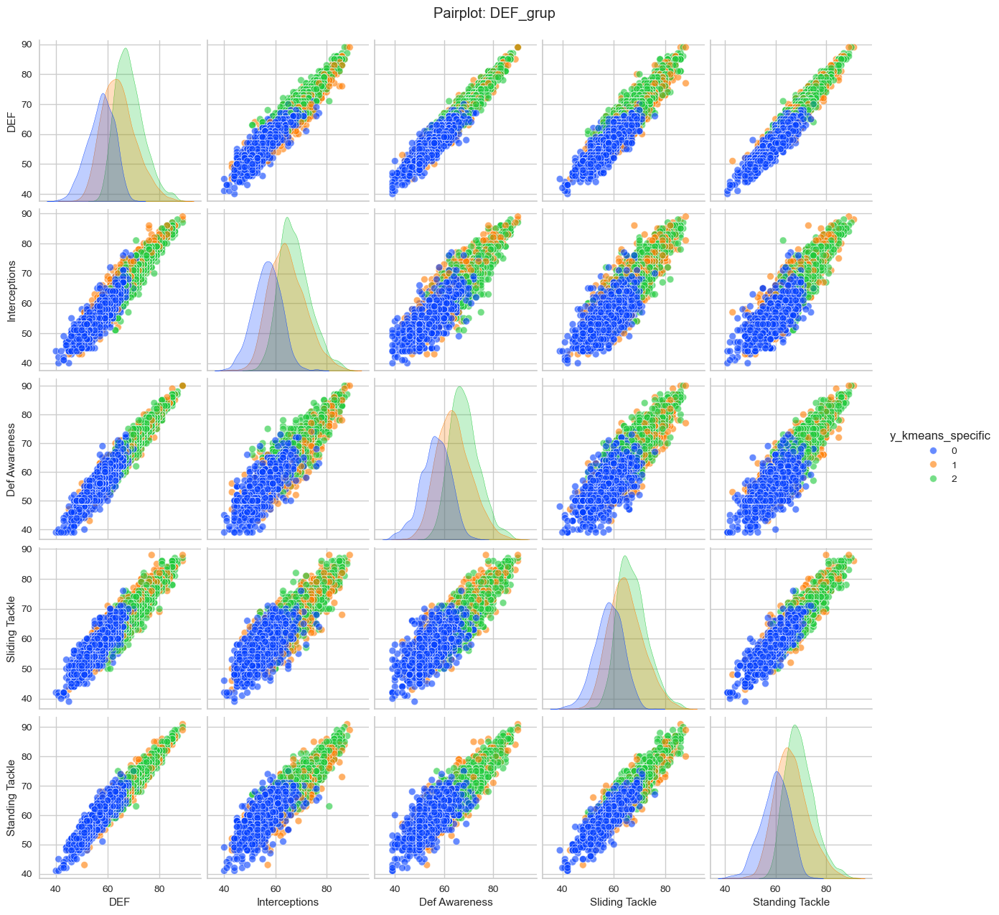

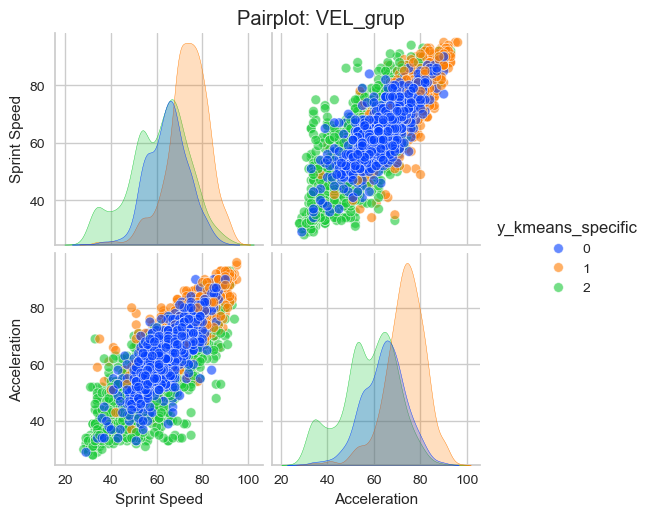

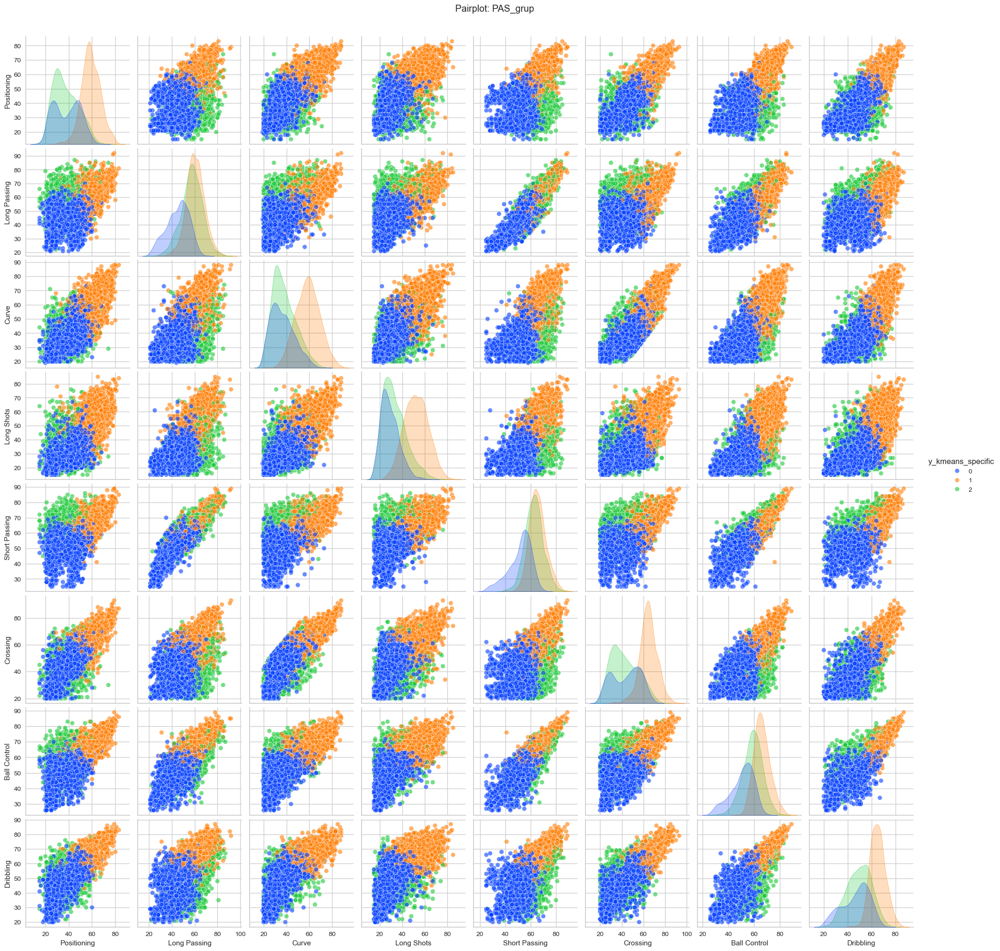

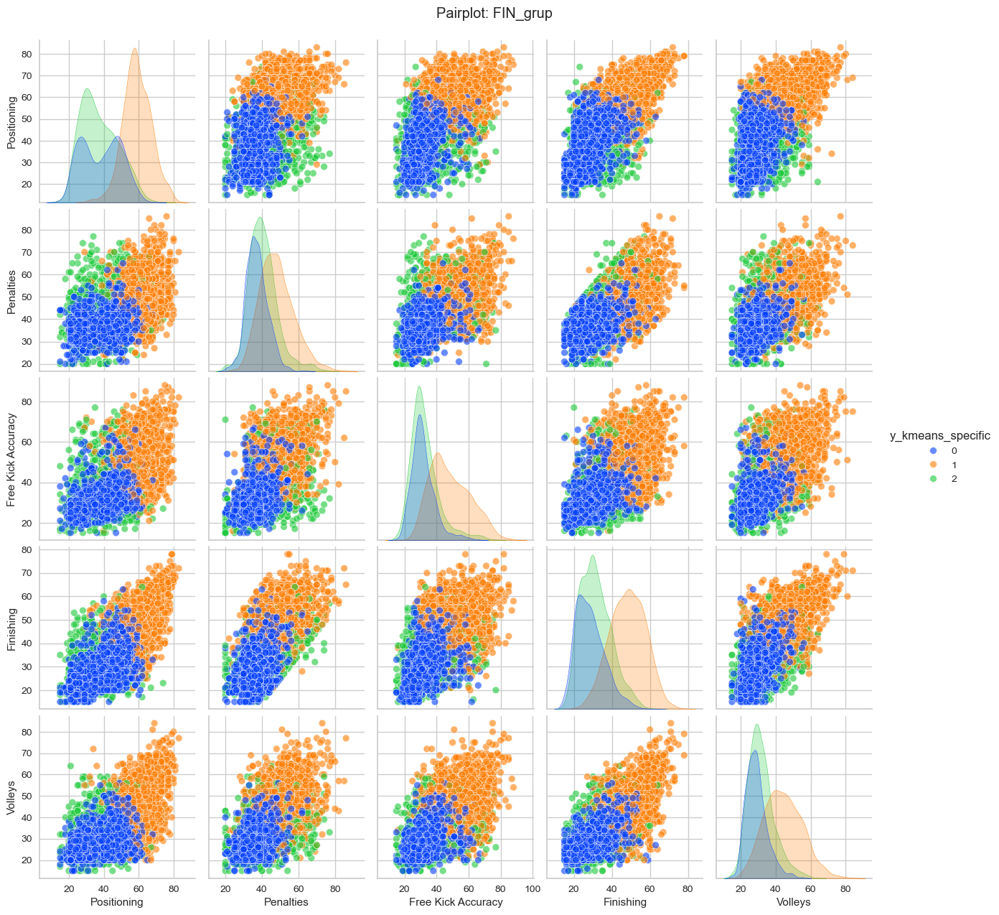

In [153]:
# Pairplots para cada grupo de variables correlacionadas
for nombre_grupo, columnas in grupos_dict.items():
    columnas_validas = [c for c in columnas if c in df_filtered_defender.columns] + ['y_kmeans_specific']
    if len(columnas_validas) < 2:
        continue  # se necesita al menos 2 variables para pairplot
    sns.pairplot(
        df_filtered_defender[columnas_validas],
        diag_kind='kde',
        plot_kws={'alpha': 0.6},
        hue='y_kmeans_specific',
        palette='bright'
    )
    plt.suptitle(f'Pairplot: {nombre_grupo}', y=1.02)
    plt.show()


In [154]:
app = dash.Dash(__name__)

# Columnas numéricas relevantes (pueden venir de df_final)
num_cols = [
    'OVR', 'PAC', 'SHO', 'PAS', 'DRI', 'DEF', 'PHY',
    'Acceleration', 'Sprint Speed', 'Positioning', 'Finishing',
    'Shot Power', 'Long Shots', 'Volleys', 'Penalties',
    'Vision', 'Crossing', 'Free Kick Accuracy', 'Short Passing',
    'Long Passing', 'Curve', 'Dribbling', 'Agility', 'Balance',
    'Reactions', 'Ball Control', 'Composure', 'Interceptions',
    'Heading Accuracy', 'Def Awareness', 'Standing Tackle',
    'Sliding Tackle', 'Jumping', 'Stamina', 'Strength',
    'Aggression', 'Weak foot', 'Skill moves', 'Age',
    'Height_cm', 'Weight_kg'
]

app.layout = html.Div([
    dcc.Dropdown(
        id='num_var',
        options=[{'label': c, 'value': c} for c in num_cols],
        value='OVR'
    ),
    dcc.Checklist(
        id='cluster_filter',
        options=[{'label': str(c), 'value': c} for c in df_filtered_defender['y_kmeans_specific'].unique()],
        value=list(df_filtered_defender['y_kmeans_specific'].unique()),  # todos los clusters seleccionados
        inline=True
    ),
    dcc.Graph(id='hist_graph')
])

@app.callback(
    dash.dependencies.Output('hist_graph', 'figure'),
    [dash.dependencies.Input('num_var', 'value'),
     dash.dependencies.Input('cluster_filter', 'value')]
)
def update_histogram(num_var, selected_clusters):
    filtered = df_filtered_defender[df_filtered_defender['y_kmeans_specific'].isin(selected_clusters)]
    fig = px.histog


In [155]:
# Filtrar los mejores dos jugadores de cada cluster según OVR
top_players_by_cluster = (
    df_filtered_defender
    .sort_values(['y_kmeans_specific', 'OVR'], ascending=[True, False])
    .groupby('y_kmeans_specific')
    .head(2)
    .loc[:, ['y_kmeans_specific', 'Name', 'Position', 'OVR', 'Team']]
    .reset_index(drop=True)
)

print(top_players_by_cluster)


   y_kmeans_specific             Name Position  OVR             Team
0                  0       Lewin Blum       RB   70   BSC Young Boys
1                  0      Dani Barcia       CB   69     RC Deportivo
2                  1  Virgil van Dijk       CB   89        Liverpool
3                  1   Theo Hernández       LB   87        Milano FC
4                  2       Rúben Dias       CB   88  Manchester City
5                  2  Antonio Rüdiger       CB   88      Real Madrid


In [156]:
# Buscar jugadores que contengan "Jara" en el nombre
df_filtered_defender[
    df_filtered_defender['Name'].str.contains('Jara', case=False, na=False)
][['Name', 'Team', 'Position', 'OVR', 'y_kmeans_specific']]


,Name,Team,Position,OVR,y_kmeans_specific
5175,Leonardo Jara,Vélez Sarsfield,RB,69,1
7731,Marvin Bejarano,Wilstermann,LB,66,1


La clusterización con **K-Means (3 clusters, PCA escalado a 15 componentes)** muestra tres perfiles distintos de defensores:

- **Cluster 0**: Predominan defensores centrales. Se caracterizan por tener mejores métricas defensivas puras, pero puntajes bajos en velocidad, definición y habilidades ofensivas. Son jugadores menos versátiles, enfocados en defensa y juego aéreo.  
- **Cluster 1**: Agrupa a laterales defensivos con buena velocidad y resistencia, pero sin destacar en definición o pase. Representan un perfil intermedio entre los centrales y los más ofensivos.  
- **Cluster 2**: Incluye defensores más versátiles, que combinan buenas métricas defensivas con velocidad y algunas habilidades ofensivas (pase y definición). Son laterales con proyección ofensiva o defensores polivalentes.  

El **histograma por posición** confirma que los centrales caen mayormente en el cluster 0, mientras que los laterales se reparten entre el 1 y el 2.  
Los **pairplots** muestran que la velocidad y el pase son los atributos que más diferencian a los grupos.  

En general, los clusters reflejan bien los distintos roles dentro de la defensa: centrales, laterales defensivos y laterales ofensivos. Esto coincide con la lógica del fútbol real.


### 3.2. Mediocampistas

In [158]:
# Filtrar mediocampistas en df
df_filtered_midfielder = df[df['Position2'] == 'Midfielder'].copy()

# Merge con df_final (features reducidas) por índice
df_filtered_midfielder = df_filtered_midfielder.merge(
    df_final,
    left_index=True, right_index=True,
    suffixes=('', '_final')
)

# Features numéricas desde df_final (evitar columnas de clusters si existieran)
feature_cols_mid = df_final.select_dtypes(include='number').columns.tolist()
feature_cols_mid = [c for c in feature_cols_mid if 'cluster' not in c.lower() and not c.startswith('Unnamed')]

# Alinear filas sin NaNs en features
mask_mid = df_filtered_midfielder[feature_cols_mid].notna().all(axis=1)
df_filtered_midfielder = df_filtered_midfielder.loc[mask_mid].copy()

# Escalado y PCA
X_mid = StandardScaler().fit_transform(df_filtered_midfielder[feature_cols_mid])
pca_mid = PCA(n_components=15, random_state=42)
dim_reduce_fit_midfielder = pca_mid.fit_transform(X_mid)

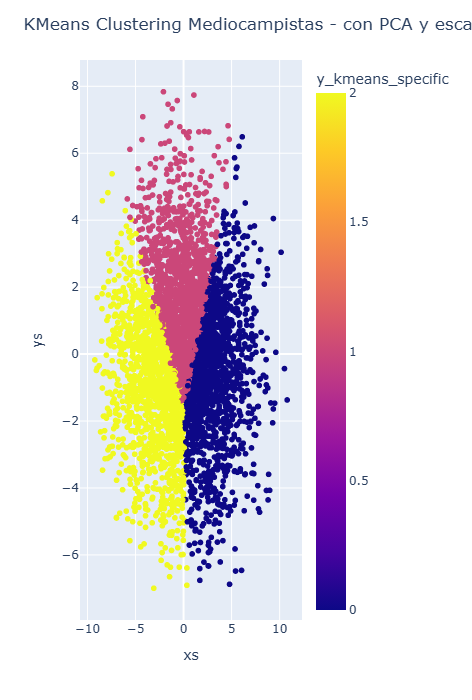

In [160]:
df_filtered_midfielder = cluster_and_visualize_filtered(
    df_filtered_midfielder,
    dim_reduce_fit_midfielder,
    title='Mediocampistas - con PCA y escalado',
    n_clusters=3
)


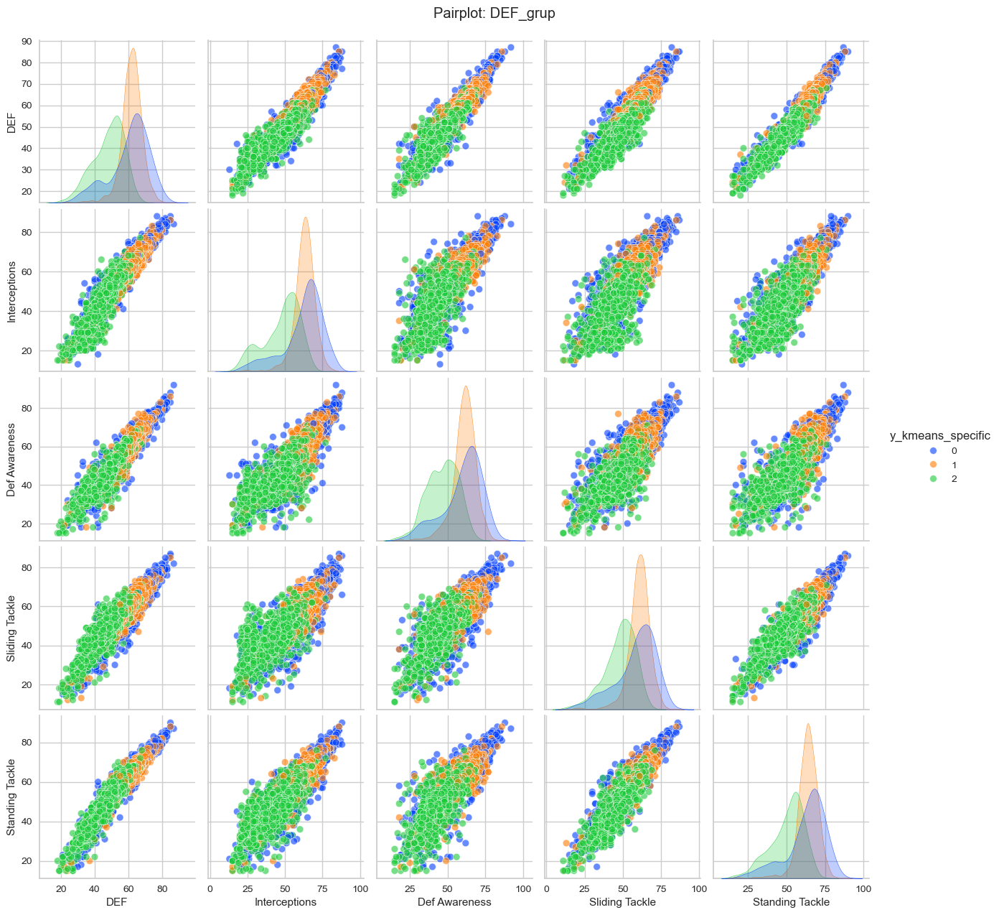

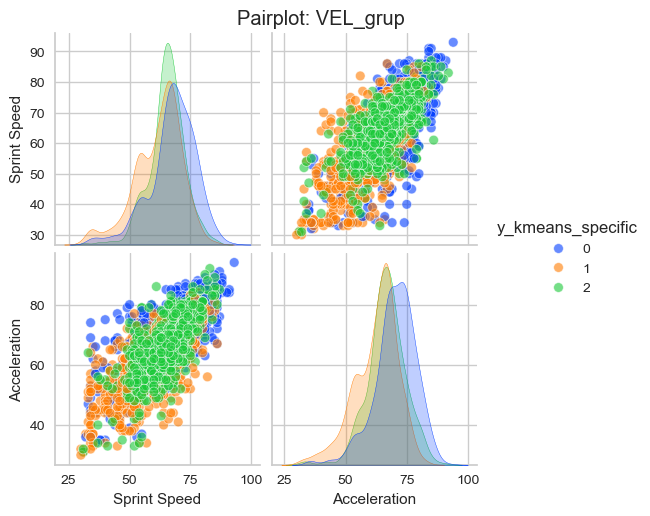

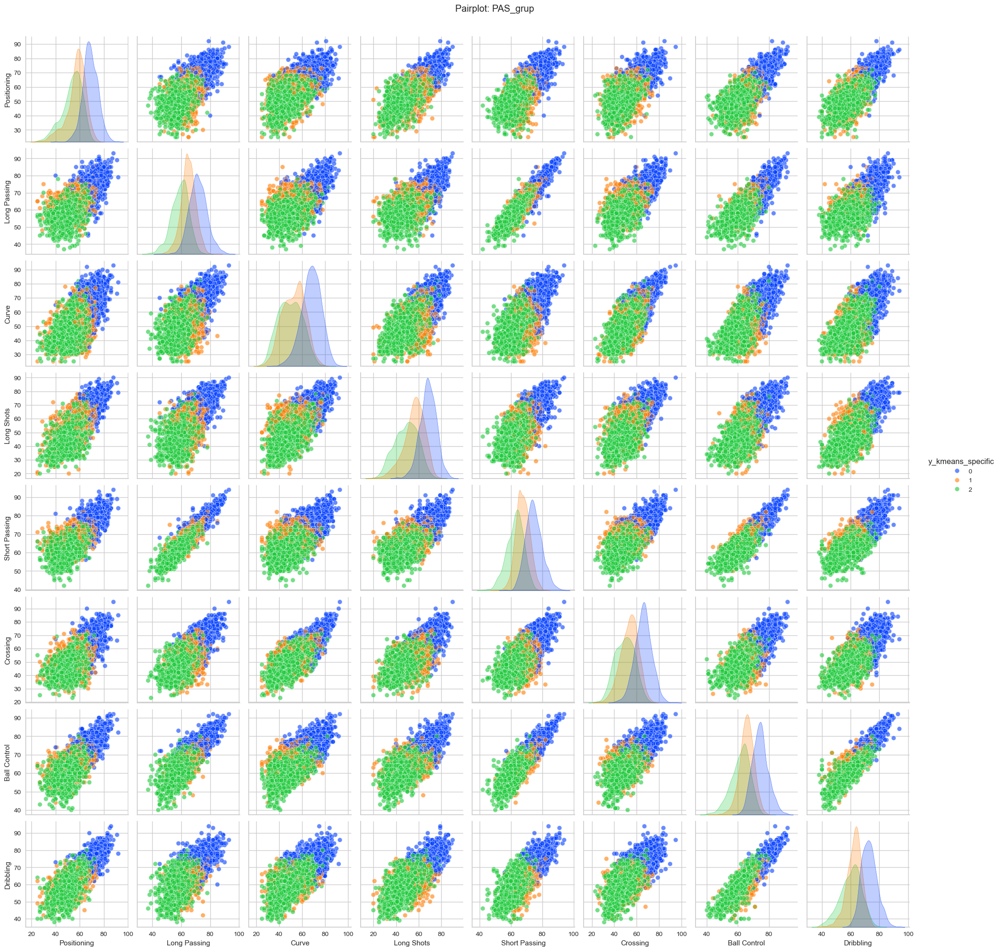

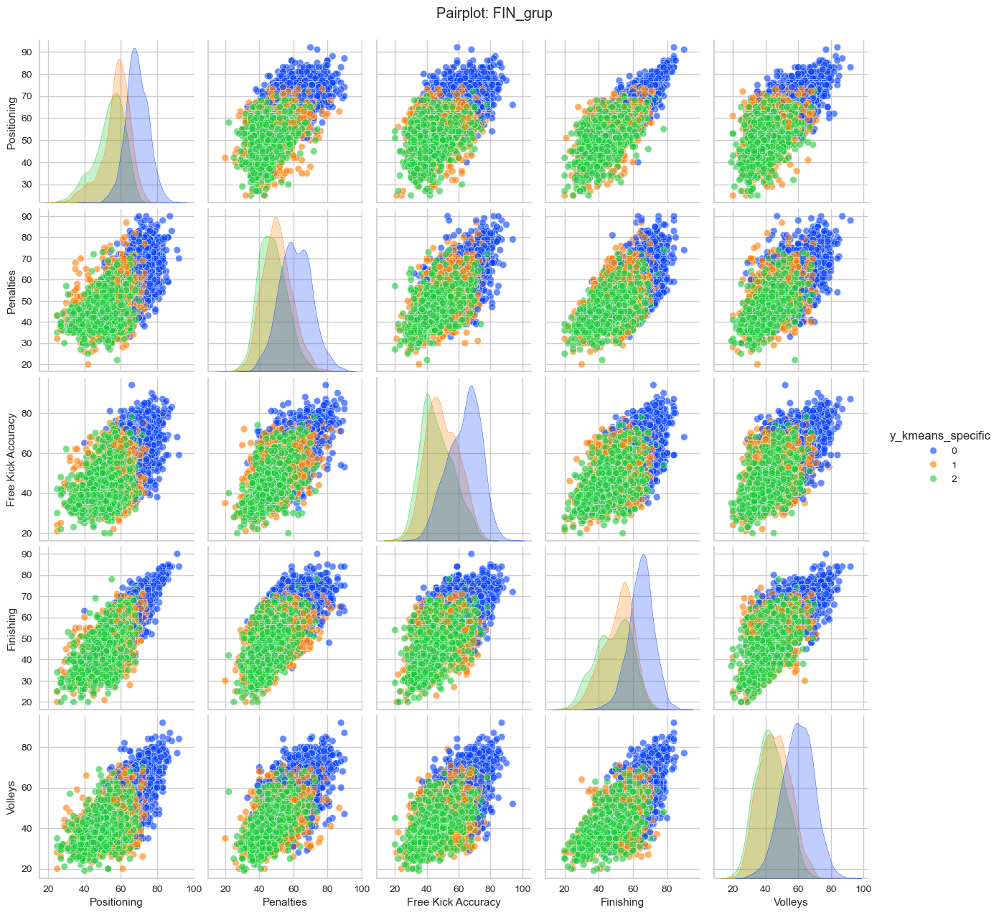

In [162]:
# Pairplots para cada grupo de variables correlacionadas
for nombre_grupo, columnas in grupos_dict.items():
    columnas_validas = [c for c in columnas if c in df.columns] + ['y_kmeans_specific']
    if len(columnas_validas) < 2:
        continue  # se necesita al menos 2 variables para pairplot
    sns.pairplot(
        df_filtered_midfielder[columnas_validas],
        diag_kind='kde',
        plot_kws={'alpha':0.6},
        hue='y_kmeans_specific',
        palette='bright'
    )
    plt.suptitle(f'Pairplot: {nombre_grupo}', y=1.02)
    plt.show()

In [163]:
app = dash.Dash(__name__)

# df_filtered_midfielder ya definido
num_cols = ['Rank', 'OVR', 'PAC', 'SHO', 'PAS', 'DRI',
       'DEF', 'PHY', 'Acceleration', 'Sprint Speed', 'Positioning',
       'Finishing', 'Shot Power', 'Long Shots', 'Volleys', 'Penalties',
       'Vision', 'Crossing', 'Free Kick Accuracy', 'Short Passing',
       'Long Passing', 'Curve', 'Dribbling', 'Agility', 'Balance', 'Reactions',
       'Ball Control', 'Composure', 'Interceptions', 'Heading Accuracy',
       'Def Awareness', 'Standing Tackle', 'Sliding Tackle', 'Jumping',
       'Stamina', 'Strength', 'Aggression', 'Weak foot', 'Skill moves', 'Age',
       'GK Diving', 'GK Handling', 'GK Kicking', 'GK Positioning',
       'GK Reflexes', 'Height_cm', 'Weight_kg', 'Position']

app.layout = html.Div([
    dcc.Dropdown(
        id='num_var',
        options=[{'label': c, 'value': c} for c in num_cols],
        value='Height_cm'
    ),
    dcc.Checklist(
        id='position_filter',
        options=[{'label': c, 'value': c} for c in df_filtered_midfielder['y_kmeans_specific'].unique()],
        value=list(df_filtered_midfielder['y_kmeans_specific'].unique()),
        inline=True
    ),
    dcc.Graph(id='hist_graph')
])

@app.callback(
    dash.dependencies.Output('hist_graph', 'figure'),
    [dash.dependencies.Input('num_var', 'value'),
     dash.dependencies.Input('position_filter', 'value')]
)
def update_histogram(num_var, selected_positions):
    filtered = df_filtered_midfielder[df_filtered_midfielder['y_kmeans_specific'].isin(selected_positions)]
    fig = px.histogram(
        filtered,
        x=num_var,
        color='y_kmeans_specific',
        barmode='overlay',
        opacity=0.6,
        nbins=30,
        histnorm='probability density'
    )
    return fig

if __name__ == '__main__':
    app.run(debug=True, port=8052)


En los pairplots vemos que los jugadores del **grupo 0** tienen menos habilidades defensivas y más velocidad.  
Esto tiene sentido porque en la distribución de posiciones específicas aparecen en posiciones de banda (mediocampistas laterales), que suelen correr más.  
Los otros clusters agrupan jugadores más equilibrados (grupo 1) o con mayor énfasis en la posesión y el pase (grupo 2).


### 3.3. Delanteros

In [164]:
# Filtrar delanteros en df
df_filtered_forward = df[df['Position2'] == 'Forward'].copy()

# Merge con df_final (features reducidas) por índice
df_filtered_forward = df_filtered_forward.merge(
    df_final,
    left_index=True, right_index=True,
    suffixes=('', '_final')
)

# Features numéricas desde df_final (evitar columnas de clusters si existieran)
feature_cols_fwd = df_final.select_dtypes(include='number').columns.tolist()
feature_cols_fwd = [c for c in feature_cols_fwd if 'cluster' not in c.lower() and not c.startswith('Unnamed')]

# Alinear filas sin NaNs en features
mask_fwd = df_filtered_forward[feature_cols_fwd].notna().all(axis=1)
df_filtered_forward = df_filtered_forward.loc[mask_fwd].copy()

# Escalado y PCA
X_fwd = StandardScaler().fit_transform(df_filtered_forward[feature_cols_fwd])
pca_fwd = PCA(n_components=15, random_state=42)
dim_reduce_fit_forward = pca_fwd.fit_transform(X_fwd)


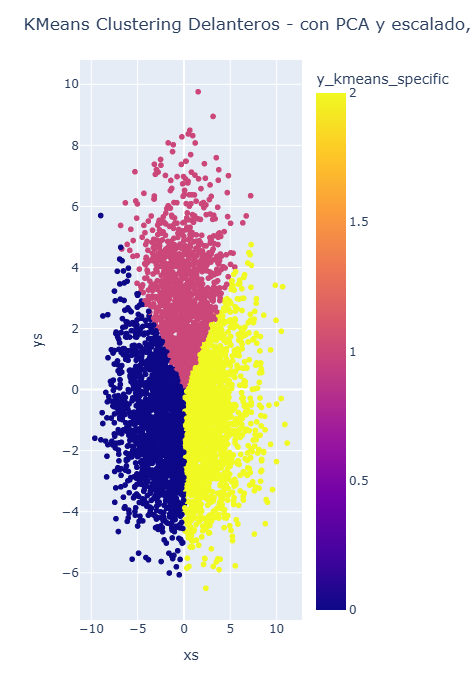

In [165]:
df_filtered_forward = cluster_and_visualize_filtered(
    df_filtered_forward,
    dim_reduce_fit_forward,
    title='Delanteros - con PCA y escalado',
    n_clusters=3
)


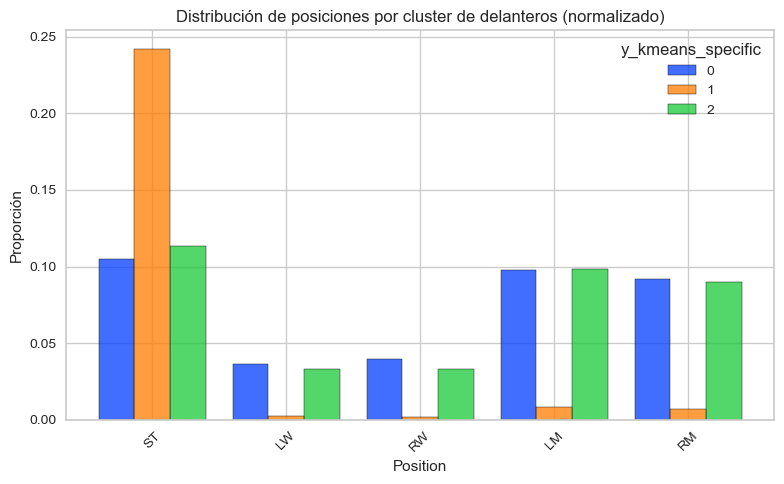

In [166]:
plt.figure(figsize=(8,5))
sns.histplot(
    data=df_filtered_forward,
    x='Position',
    hue='y_kmeans_specific',
    multiple='dodge',
    shrink=0.8,
    stat='probability',
    discrete=True,
    palette='bright'
)
plt.title('Distribución de posiciones por cluster de delanteros (normalizado)')
plt.xlabel('Position')
plt.ylabel('Proporción')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

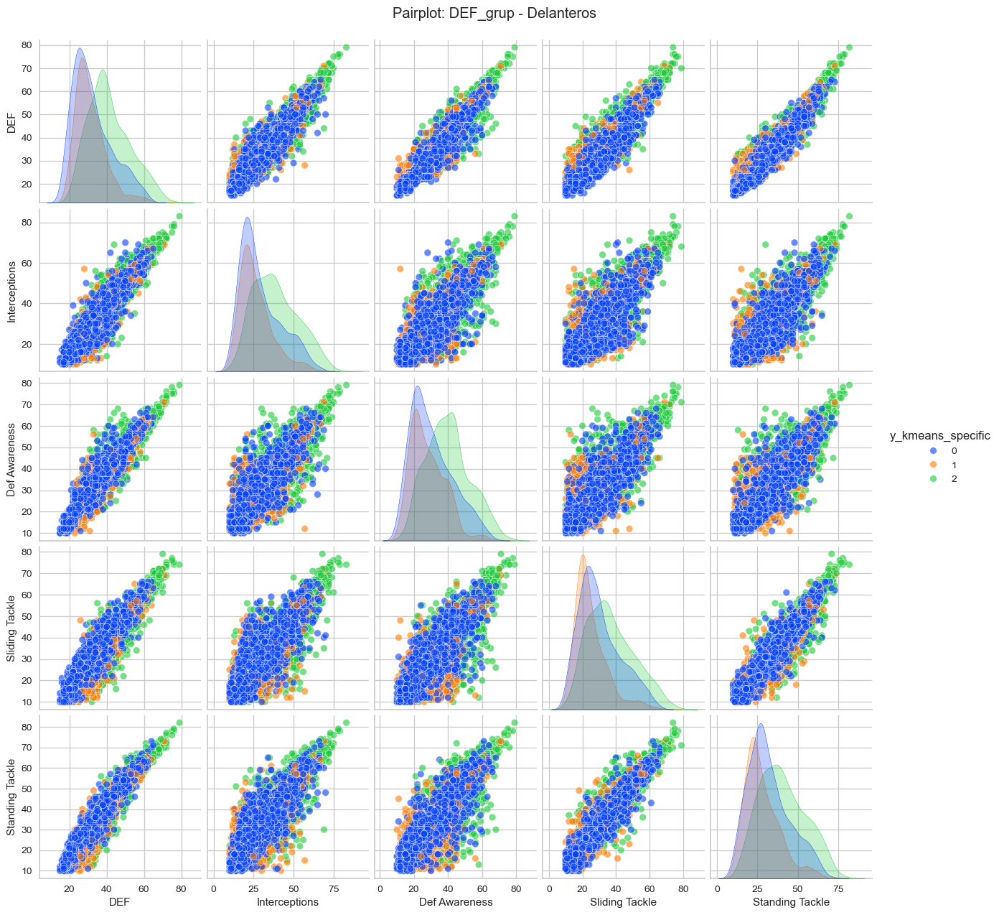

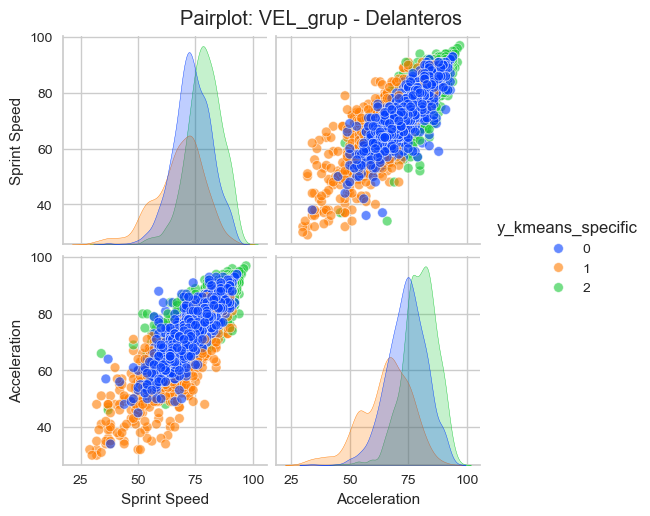

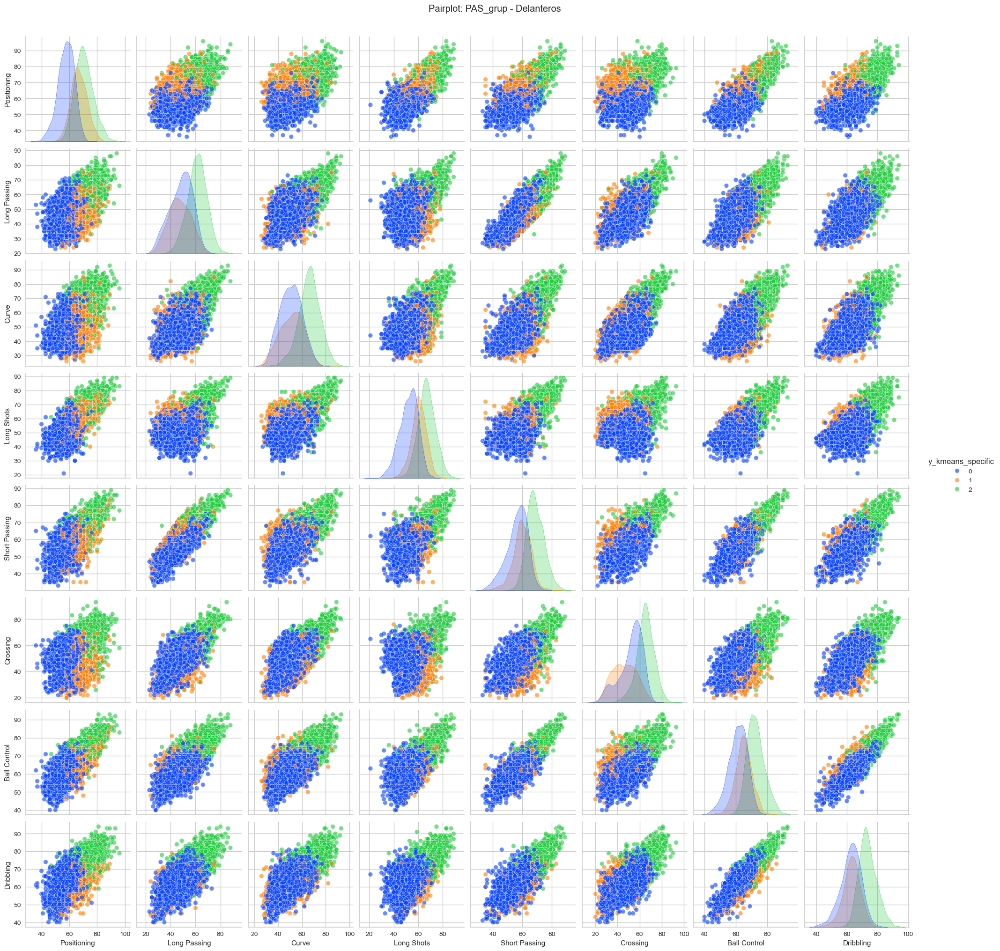

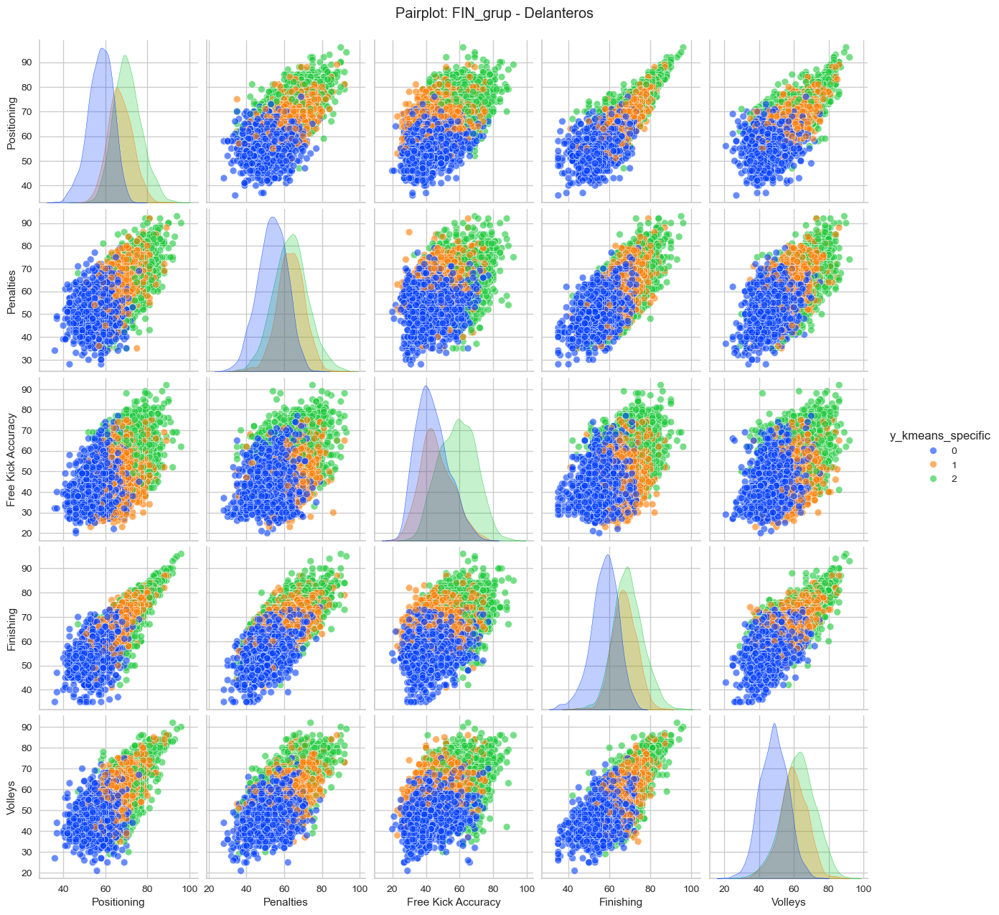

In [167]:
for nombre_grupo, columnas in grupos_dict.items():
    columnas_validas = [c for c in columnas if c in df_filtered_forward.columns] + ['y_kmeans_specific']
    if len(columnas_validas) < 2:
        continue
    sns.pairplot(
        df_filtered_forward[columnas_validas],
        diag_kind='kde',
        plot_kws={'alpha':0.6},
        hue='y_kmeans_specific',
        palette='bright'
    )
    plt.suptitle(f'Pairplot: {nombre_grupo} - Delanteros', y=1.02)
    plt.show()

In [168]:
app = dash.Dash(__name__)

num_cols = df_final.select_dtypes(include='number').columns.tolist() + ['Position']

app.layout = html.Div([
    dcc.Dropdown(
        id='num_var',
        options=[{'label': c, 'value': c} for c in num_cols],
        value='OVR'
    ),
    dcc.Checklist(
        id='position_filter',
        options=[{'label': c, 'value': c} for c in df_filtered_forward['y_kmeans_specific'].unique()],
        value=list(df_filtered_forward['y_kmeans_specific'].unique()),
        inline=True
    ),
    dcc.Graph(id='hist_graph')
])

@app.callback(
    dash.dependencies.Output('hist_graph', 'figure'),
    [dash.dependencies.Input('num_var', 'value'),
     dash.dependencies.Input('position_filter', 'value')]
)
def update_histogram(num_var, selected_positions):
    filtered = df_filtered_forward[df_filtered_forward['y_kmeans_specific'].isin(selected_positions)]
    fig = px.histogram(
        filtered,
        x=num_var,
        color='y_kmeans_specific',
        barmode='overlay',
        opacity=0.6,
        nbins=30,
        histnorm='probability density'
    )
    return fig

if __name__ == '__main__':
    app.run(debug=True, port=8051)

En el caso de los delanteros, los clusters no muestran una segmentación tan clara como en defensores o mediocampistas.
Más allá de la posición específica (ST, RW, LW, etc.), el gráfico interactivo sugiere que la principal diferencia entre grupos está asociada al OVR, lo que implica que el modelo está separando más por nivel general de rendimiento que por estilo de juego.